# StyleForge — Industry-Level Image Generation System
### Autoencoder + β-VAE + Conditional GAN · Gen AI-MDM · IA Activity 1




In [1]:
# ============================ 0. SETUP & CONFIGURATION ============================
import os, sys, time, json, math, random, copy, subprocess, warnings, inspect, datetime, importlib, importlib.util, hashlib
warnings.filterwarnings("ignore")

def _pip(*pkgs):
    try:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", *pkgs], check=False)
    except Exception as e:
        print("pip install failed:", e)

for _mod, _pkgs in [("scipy", ["scipy"]), ("matplotlib", ["matplotlib"]), ("reportlab", ["reportlab"]),
                    ("lpips", ["lpips"]), ("fastapi", ["fastapi", "httpx"])]:
    if importlib.util.find_spec(_mod) is None:
        _pip(*_pkgs)

import numpy as np
import matplotlib.pyplot as plt
import torch, torch.nn as nn, torch.nn.functional as F
import torchvision
from scipy import linalg

# ---------------- run configuration ----------------
MODE = "fast"            # "smoke" | "fast" | "demo" | "full"
RUN_ABLATIONS = (MODE in ('demo', 'full'))     # experiments E3, E4, E5 (short runs)
RUN_E1 = False           # E1 trains 2 extra autoencoders (slow) - set True if you want it
if torch.cuda.is_available(): torch.backends.cudnn.benchmark = True
SEED = 42
STUDENT = dict(name="Divya Thawkar", roll="202301070082", division="T4",
               dept="Electronics and Telecommunication", year="2026–27")

PRESETS = {
    "smoke": dict(ae=1,  vae=1,   gan=2,   abl=1,  sweep=[1.0],                    n_eval=1000,  n_gen=1000,  train_sub=6000, gan_eval_every=1),
    "fast":  dict(ae=4,  vae=4,   gan=10,  abl=2,  sweep=[1.0],                    n_eval=2000,  n_gen=2000,  train_sub=15000, gan_eval_every=5),
    "demo":  dict(ae=6,  vae=15,  gan=40,  abl=5,  sweep=[0.5, 1.0, 4.0],          n_eval=5000,  n_gen=5000,  train_sub=None, gan_eval_every=5),
    "full":  dict(ae=60, vae=100, gan=200, abl=20, sweep=[0.1, 0.5, 1.0, 2.0, 4.0], n_eval=10000, n_gen=10000, train_sub=None, gan_eval_every=10),
}
P = PRESETS[MODE]

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
AMP = DEVICE.type == "cuda"
GPU_NAME = torch.cuda.get_device_name(0) if AMP else "CPU"
if not AMP:
    print("WARNING: no GPU detected. Use MODE='smoke' or switch the runtime to a GPU.")

OUT, FIG, ART = "styleforge_outputs", "styleforge_outputs/figs", "styleforge/artifacts"
for d in (OUT, FIG, ART, "styleforge/service", "data"):
    os.makedirs(d, exist_ok=True)
open("styleforge/__init__.py", "w").write("")
open("styleforge/service/__init__.py", "w").write("")

# Hyper-parameters (starting points from the design document; Section 10 of the report)
CFG = dict(
    ae =dict(z=128, batch=128, lr=1e-3, wd=1e-4, lam1=1.0, lam_s=0.2),
    vae=dict(z=64,  batch=128, lr=5e-4, wd=1e-4, warm_epochs=10, free_bits=0.05),
    gan=dict(z=128, emb=32, ch_g=512, ch_d=64, batch=64, lr_d=4e-4, lr_g=1e-4, betas=(0.0, 0.9), ema=0.999),
)

RES, TIMES = {}, {}      # everything measured in this notebook is stored here -> used by the report

def set_seed(s=SEED):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
set_seed()

print(f"mode={MODE} | device={GPU_NAME} | torch {torch.__version__} | torchvision {torchvision.__version__}")
print("epochs  AE/VAE/GAN:", P["ae"], P["vae"], P["gan"], "| beta sweep:", P["sweep"])

mode=fast | device=Tesla T4 | torch 2.14.1+cu130 | torchvision 0.29.1+cu130
epochs  AE/VAE/GAN: 4 4 10 | beta sweep: [1.0]


In [2]:
%%writefile styleforge/models.py
"""StyleForge model library - written by the notebook, imported by the notebook AND the FastAPI service."""
import math
import torch, torch.nn as nn, torch.nn.functional as F
from torch.nn.utils import spectral_norm as SN

CLASSES = ["T-shirt/top", "Trouser", "Pullover", "Dress", "Coat", "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"]
FLIP_OK = (0, 1, 2, 3, 4, 6, 8)          # categories that are left/right symmetric


# ------------------------------------------------------------------ preprocessing
def prep(xb):
    """uint8 (B,28,28) -> float (B,3,64,64) in [-1,1] (resize + replicate to 3 channels)."""
    x = xb.float().div(127.5).sub(1).unsqueeze(1)
    x = F.interpolate(x, size=64, mode="bilinear", align_corners=False)
    return x.expand(-1, 3, -1, -1).contiguous()


def augment_ae(x, y, shift=2):
    """AE/VAE augmentation: small random translation (+-2 px, drawn per batch) and
    horizontal flip only for symmetric categories."""
    if shift > 0:
        xp = F.pad(x, (shift,) * 4, mode="replicate")
        i, j = (int(v) for v in torch.randint(0, 2 * shift + 1, (2,)))
        x = xp[:, :, i:i + x.size(2), j:j + x.size(3)]
    ok = torch.zeros_like(y, dtype=torch.bool)
    for c in FLIP_OK:
        ok |= (y == c)
    flip = ok & (torch.rand(y.shape, device=y.device) < 0.5)
    return torch.where(flip.view(-1, 1, 1, 1), x.flip(3), x)


def diff_augment(x):
    """Differentiable augmentation (Zhao et al., 2020): colour jitter, translation, cutout."""
    B, dev = x.size(0), x.device
    x = x + (torch.rand(B, 1, 1, 1, device=dev) - 0.5)                                   # brightness
    m = x.mean(1, keepdim=True)
    x = (x - m) * (torch.rand(B, 1, 1, 1, device=dev) * 2) + m                            # saturation
    m = x.mean(dim=(1, 2, 3), keepdim=True)
    x = (x - m) * (torch.rand(B, 1, 1, 1, device=dev) + 0.5) + m                          # contrast
    t = (torch.rand(B, 2, device=dev) - 0.5) * 2 * 0.25                                   # translation, 12.5 % of width
    theta = torch.zeros(B, 2, 3, device=dev)
    theta[:, 0, 0] = 1; theta[:, 1, 1] = 1; theta[:, :, 2] = t
    grid = F.affine_grid(theta, list(x.shape), align_corners=False)
    x = F.grid_sample(x, grid, mode="bilinear", padding_mode="zeros", align_corners=False)
    H = x.size(2)                                                                         # cutout (half-size square)
    cy = torch.randint(0, H, (B, 1, 1), device=dev); cx = torch.randint(0, H, (B, 1, 1), device=dev)
    ar = torch.arange(H, device=dev)
    keep = ~(((ar.view(1, H, 1) - cy).abs() < H / 4) & ((ar.view(1, 1, H) - cx).abs() < H / 4))
    return x * keep.unsqueeze(1).to(x.dtype)


# ------------------------------------------------------------------ SSIM
def _gauss_win(ws, sigma, ch, device):
    g = torch.arange(ws, dtype=torch.float32, device=device) - ws // 2
    g = torch.exp(-g ** 2 / (2 * sigma ** 2)); g = g / g.sum()
    return (g[:, None] * g[None, :]).expand(ch, 1, ws, ws).contiguous()


def ssim(x, y, ws=11, sigma=1.5, per_image=False):
    """Structural similarity for images in [-1,1]."""
    x = (x.float() + 1) / 2; y = (y.float() + 1) / 2
    ch, p = x.size(1), ws // 2
    w = _gauss_win(ws, sigma, ch, x.device)
    mx = F.conv2d(x, w, padding=p, groups=ch); my = F.conv2d(y, w, padding=p, groups=ch)
    sxx = F.conv2d(x * x, w, padding=p, groups=ch) - mx * mx
    syy = F.conv2d(y * y, w, padding=p, groups=ch) - my * my
    sxy = F.conv2d(x * y, w, padding=p, groups=ch) - mx * my
    C1, C2 = 0.01 ** 2, 0.03 ** 2
    s = ((2 * mx * my + C1) * (2 * sxy + C2)) / ((mx * mx + my * my + C1) * (sxx + syy + C2))
    return s.flatten(1).mean(1) if per_image else s.mean()


# ------------------------------------------------------------------ Autoencoder / VAE
class ResBlock(nn.Module):
    def __init__(self, ch):
        super().__init__()
        self.body = nn.Sequential(
            nn.GroupNorm(8, ch), nn.SiLU(), nn.Conv2d(ch, ch, 3, padding=1),
            nn.GroupNorm(8, ch), nn.SiLU(), nn.Conv2d(ch, ch, 3, padding=1))

    def forward(self, x):
        return x + self.body(x)


def down(cin, cout):
    return nn.Sequential(nn.Conv2d(cin, cout, 4, 2, 1), ResBlock(cout))


def up(cin, cout):
    return nn.Sequential(nn.Upsample(scale_factor=2, mode="nearest"),
                         nn.Conv2d(cin, cout, 3, padding=1), ResBlock(cout))


def _encoder():
    return nn.Sequential(nn.Conv2d(3, 32, 3, padding=1), down(32, 64), down(64, 128), down(128, 256), down(256, 256))


def _decoder():
    return nn.Sequential(up(256, 256), up(256, 128), up(128, 64), up(64, 32),
                         nn.GroupNorm(8, 32), nn.SiLU(), nn.Conv2d(32, 3, 3, padding=1), nn.Tanh())


class ConvAutoencoder(nn.Module):
    def __init__(self, z_dim=128):
        super().__init__()
        self.enc = _encoder()
        self.to_z = nn.Linear(256 * 4 * 4, z_dim)
        self.from_z = nn.Linear(z_dim, 256 * 4 * 4)
        self.dec = _decoder()

    def encode(self, x):
        return self.to_z(self.enc(x).flatten(1))

    def decode(self, z):
        return self.dec(self.from_z(z).view(-1, 256, 4, 4))

    def forward(self, x):
        z = self.encode(x)
        return self.decode(z), z


class ConvVAE(nn.Module):
    """Same encoder trunk / decoder as the Autoencoder, two linear heads (mu, logvar)."""
    def __init__(self, z_dim=64):
        super().__init__()
        self.enc = _encoder()
        self.fc_mu = nn.Linear(256 * 4 * 4, z_dim)
        self.fc_logvar = nn.Linear(256 * 4 * 4, z_dim)
        self.from_z = nn.Linear(z_dim, 256 * 4 * 4)
        self.dec = _decoder()

    def encode(self, x):
        h = self.enc(x).flatten(1)
        return self.fc_mu(h), self.fc_logvar(h).clamp(-12, 8)          # clamp keeps exp(logvar) finite in fp16/fp32

    def decode(self, z):
        return self.dec(self.from_z(z).view(-1, 256, 4, 4))

    def forward(self, x):
        mu, logvar = self.encode(x)
        z = mu + torch.randn_like(mu) * torch.exp(0.5 * logvar)      # reparameterisation trick
        return self.decode(z), mu, logvar


def vae_loss(x_hat, x, mu, logvar, beta, free_bits=0.0):
    b = x.size(0)
    recon = F.l1_loss(x_hat, x, reduction="sum") / b                          # per-image
    kl_dim = -0.5 * (1 + logvar - mu.pow(2) - logvar.exp()).mean(dim=0)
    kl = torch.clamp(kl_dim, min=free_bits).sum()                             # free bits
    return recon + beta * kl, recon.detach(), kl_dim.sum().detach()


def beta_schedule(step, warmup_steps, beta_max):
    return beta_max * min(1.0, step / max(1, warmup_steps))


def slerp(z0, z1, t):
    z0n = z0 / z0.norm(dim=-1, keepdim=True)
    z1n = z1 / z1.norm(dim=-1, keepdim=True)
    omega = torch.acos((z0n * z1n).sum(-1).clamp(-1 + 1e-7, 1 - 1e-7))
    so = torch.sin(omega)
    a = (torch.sin((1 - t) * omega) / so).unsqueeze(-1)
    b = (torch.sin(t * omega) / so).unsqueeze(-1)
    return a * z0 + b * z1


# ------------------------------------------------------------------ Conditional GAN
class GBlock(nn.Module):
    def __init__(self, cin, cout):
        super().__init__()
        self.net = nn.Sequential(nn.Upsample(scale_factor=2, mode="nearest"),
                                 nn.Conv2d(cin, cout, 3, padding=1), nn.BatchNorm2d(cout), nn.ReLU(True))

    def forward(self, x):
        return self.net(x)


class Generator(nn.Module):
    def __init__(self, z_dim=128, n_classes=10, emb_dim=32, ch=512):
        super().__init__()
        self.ch = ch
        self.emb = nn.Embedding(n_classes, emb_dim)
        self.fc = nn.Linear(z_dim + emb_dim, ch * 4 * 4)
        self.blocks = nn.Sequential(GBlock(ch, ch // 2), GBlock(ch // 2, ch // 4),      # 4 -> 8 -> 16 -> 32 -> 64
                                    GBlock(ch // 4, ch // 8), GBlock(ch // 8, ch // 16))
        self.out = nn.Sequential(nn.Conv2d(ch // 16, 3, 3, padding=1), nn.Tanh())

    def forward(self, z, y):
        h = self.fc(torch.cat([z, self.emb(y)], dim=1)).view(-1, self.ch, 4, 4)
        return self.out(self.blocks(h))


class Discriminator(nn.Module):
    def __init__(self, n_classes=10, ch=64):
        super().__init__()

        def blk(cin, cout):
            return nn.Sequential(SN(nn.Conv2d(cin, cout, 4, 2, 1)), nn.LeakyReLU(0.2, True))

        self.features = nn.Sequential(                                                  # 64 -> 32 -> 16 -> 8 -> 4
            SN(nn.Conv2d(3, ch, 3, padding=1)), nn.LeakyReLU(0.2, True),
            blk(ch, ch * 2), blk(ch * 2, ch * 4), blk(ch * 4, ch * 8), blk(ch * 8, ch * 8))
        self.linear = SN(nn.Linear(ch * 8, 1))
        self.embed = SN(nn.Embedding(n_classes, ch * 8))

    def forward(self, x, y):
        h = self.features(x).sum(dim=(2, 3))                                            # global sum pooling
        return self.linear(h).squeeze(1) + (self.embed(y) * h).sum(dim=1)              # projection discriminator


def d_step(D, G, real, y, z_dim, opt_D, aug):
    z = torch.randn(real.size(0), z_dim, device=real.device)
    with torch.no_grad():
        fake = G(z, y)
    loss_real = F.relu(1.0 - D(aug(real), y)).mean()
    loss_fake = F.relu(1.0 + D(aug(fake), y)).mean()
    loss_d = loss_real + loss_fake
    opt_D.zero_grad(set_to_none=True)
    loss_d.backward()
    opt_D.step()
    return loss_d.item()


def g_step(D, G, y, z_dim, opt_G, aug):
    z = torch.randn(y.size(0), z_dim, device=y.device)
    loss_g = -D(aug(G(z, y)), y).mean()
    opt_G.zero_grad(set_to_none=True)
    loss_g.backward()
    opt_G.step()
    return loss_g.item()


@torch.no_grad()
def ema_update(G_ema, G, decay=0.999):
    for pe, p in zip(G_ema.parameters(), G.parameters()):
        pe.lerp_(p, 1 - decay)
    for be, b in zip(G_ema.buffers(), G.buffers()):
        be.copy_(b)

Overwriting styleforge/models.py


## 1 · Library import and data (report Section 5)
The model library is written to `styleforge/models.py` by the previous cell so that the notebook *and* the FastAPI service import exactly the same code.

train/val/test: 15000 5000 10000 | classes: ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat', 'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']
exact duplicate images in raw training file: 0 | class balance (train): [1456, 1510, 1493, 1513, 1531, 1516, 1509, 1532, 1453, 1487]


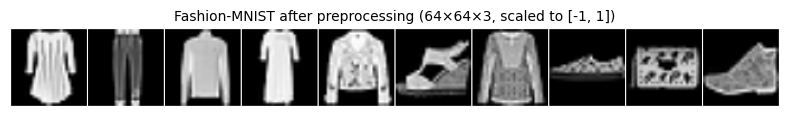

In [3]:
# ============================ 1. IMPORT LIBRARY + DATA (Section 5) ============================
sys.path.insert(0, os.getcwd())
import styleforge.models as SFM
importlib.reload(SFM)
from styleforge.models import *
from torchvision import datasets

DATASET_VERSION = f"fashion-mnist | 55,000/5,000/10,000 split | seed {SEED}"
tr_raw = datasets.FashionMNIST("data", train=True,  download=True)
te_raw = datasets.FashionMNIST("data", train=False, download=True)

g = torch.Generator().manual_seed(SEED)
perm = torch.randperm(len(tr_raw.data), generator=g)
val_idx, tr_idx = perm[:5000], perm[5000:]
Xtr, Ytr = tr_raw.data[tr_idx], tr_raw.targets[tr_idx]
Xval, Yval = tr_raw.data[val_idx], tr_raw.targets[val_idx]
Xte, Yte = te_raw.data, te_raw.targets
if P["train_sub"]:
    Xtr, Ytr = Xtr[:P["train_sub"]], Ytr[:P["train_sub"]]
Xtr, Ytr, Xval, Yval, Xte, Yte = [t.to(DEVICE) for t in (Xtr, Ytr, Xval, Yval, Xte, Yte)]
print("train/val/test:", len(Xtr), len(Xval), len(Xte), "| classes:", CLASSES)

def batches(X, Y, bs, shuffle=True, drop_last=False):
    n = len(X)
    idx = torch.randperm(n, device=X.device) if shuffle else torch.arange(n, device=X.device)
    stop = n - (n % bs) if drop_last else n
    for i in range(0, stop, bs):
        j = idx[i:i + bs]
        yield X[j], Y[j]

def grid_fig(imgs, nrow=10, title=None, path=None, scale=0.8):
    imgs = imgs.float().cpu()
    g_ = torchvision.utils.make_grid(((imgs + 1) / 2).clamp(0, 1), nrow=nrow, padding=1, pad_value=1.0)
    rows = math.ceil(len(imgs) / nrow)
    plt.figure(figsize=(max(3, nrow * scale), max(1.5, rows * scale + (0.4 if title else 0))))
    plt.imshow(g_.permute(1, 2, 0).numpy()); plt.axis("off")
    if title: plt.title(title, fontsize=10)
    plt.tight_layout()
    if path: plt.savefig(path, dpi=160, bbox_inches="tight")
    plt.show()

# ---- cleaning & screening statistics (exact duplicates; outliers are flagged after the AE is trained) ----
_arr = tr_raw.data.numpy()
_h = [hashlib.md5(_arr[i].tobytes()).hexdigest() for i in range(len(_arr))]
n_exact_dup = len(_h) - len(set(_h))
bal = torch.bincount(Ytr.cpu(), minlength=10).tolist()
RES["data"] = dict(version=DATASET_VERSION, n_train=len(Xtr), n_val=len(Xval), n_test=len(Xte),
                   exact_duplicates_in_raw_train=n_exact_dup, class_balance_train=bal)
print("exact duplicate images in raw training file:", n_exact_dup, "| class balance (train):", bal)

# one example per class, resized exactly as the models see them
ex = torch.stack([prep(Xtr[(Ytr == c).nonzero()[0]])[0] for c in range(10)])
grid_fig(ex, 10, "Fashion-MNIST after preprocessing (64×64×3, scaled to [-1, 1])", f"{FIG}/fig_samples_real.png")

## 2 · Residual Autoencoder (Section 6)
Train → reconstruct → outlier gate → find-similar → experiment E1 (SSIM term).

Training the Autoencoder ...
  AE ep   1/4  train nan  val 0.3666  (val L1 0.2492, SSIM 0.413)
  AE ep   2/4  train nan  val nan  (val L1 nan, SSIM nan)
  AE ep   3/4  train nan  val nan  (val L1 nan, SSIM nan)
  AE ep   4/4  train nan  val nan  (val L1 nan, SSIM nan)
AE test  L1 0.2500 | PSNR 14.20 dB | SSIM 0.412 | precision@10 0.615


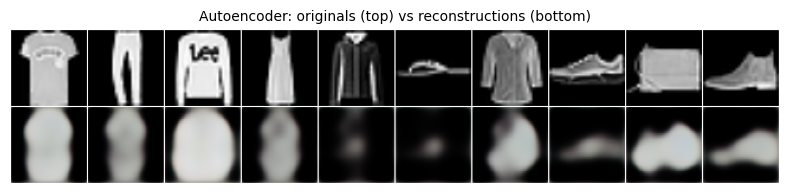

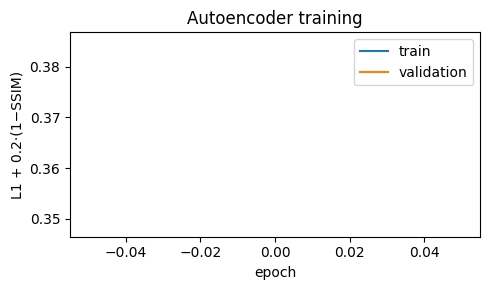

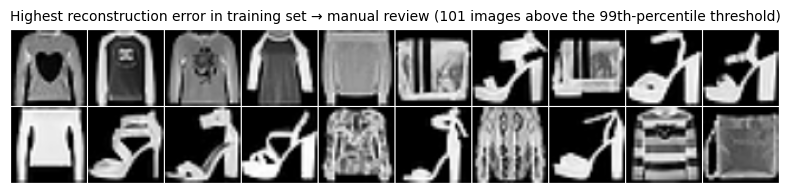

outlier gate: threshold 0.4621 -> 101 of 15000 training images flagged for review


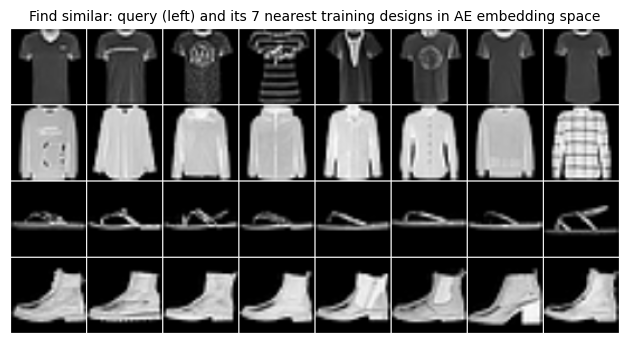

In [4]:
# ============================ 2. RESIDUAL AUTOENCODER (Section 6) ============================
@torch.no_grad()
def eval_recon(model, X, Y, bs=500, vae=False):
    model.eval(); L1, PS, SS = [], [], []
    for xb, _ in batches(X, Y, bs, shuffle=False):
        x = prep(xb)
        xh = (model.decode(model.encode(x)[0]) if vae else model(x)[0]).float()
        mse = ((x - xh) ** 2).flatten(1).mean(1)
        L1.append((x - xh).abs().flatten(1).mean(1))
        PS.append(10 * torch.log10(4.0 / mse.clamp_min(1e-10)))        # images in [-1,1] -> MAX = 2 -> MAX^2 = 4
        SS.append(ssim(x, xh, per_image=True))
    L1, PS, SS = torch.cat(L1), torch.cat(PS), torch.cat(SS)
    return dict(l1=L1.mean().item(), psnr=PS.mean().item(), ssim=SS.mean().item(), l1_all=L1.cpu().numpy())

def train_ae(epochs, use_ssim=True, verbose=True):
    set_seed(); c = CFG["ae"]
    model = ConvAutoencoder(c["z"]).to(DEVICE)
    spe = math.ceil(len(Xtr) / c["batch"])
    opt = torch.optim.AdamW(model.parameters(), lr=c["lr"], weight_decay=c["wd"])
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=max(1, epochs * spe))
    scaler = torch.amp.GradScaler("cuda", enabled=AMP)
    hist, best, t0 = dict(train=[], val=[]), (float("inf"), None), time.time()
    for ep in range(1, epochs + 1):
        model.train(); tot = torch.zeros((), device=DEVICE); n = 0
        for xb, yb in batches(Xtr, Ytr, c["batch"]):
            x = augment_ae(prep(xb), yb)
            with torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=AMP):
                xh, _ = model(x)
            xh = xh.float()
            loss = c["lam1"] * (x - xh).abs().mean()
            if use_ssim:
                loss = loss + c["lam_s"] * (1 - ssim(x, xh))
            opt.zero_grad(set_to_none=True); scaler.scale(loss).backward(); scaler.step(opt); scaler.update(); sched.step()
            tot += loss.detach() * len(x); n += len(x)
        tot = tot.item()
        r = eval_recon(model, Xval, Yval)
        vloss = c["lam1"] * r["l1"] + c["lam_s"] * (1 - r["ssim"])      # same selection criterion for every variant
        hist["train"].append(tot / n); hist["val"].append(vloss)
        if vloss < best[0]:
            best = (vloss, copy.deepcopy(model.state_dict()))
        if verbose: print(f"  AE ep {ep:3d}/{epochs}  train {tot/n:.4f}  val {vloss:.4f}  (val L1 {r['l1']:.4f}, SSIM {r['ssim']:.3f})")
    model.load_state_dict(best[1]); model.eval()
    return model, hist, time.time() - t0

@torch.no_grad()
def embed_u8(model, X, bs=1000, vae=False):
    model.eval(); out = []
    for i in range(0, len(X), bs):
        z = model.encode(prep(X[i:i + bs])); z = z[0] if vae else z
        out.append(z.float())
    return torch.cat(out)

@torch.no_grad()
def embed_imgs(model, imgs, bs=1000):
    """AE embeddings of float images in [-1,1] (CPU or GPU) -> GPU tensor."""
    model.eval(); out = []
    for i in range(0, len(imgs), bs):
        out.append(model.encode(imgs[i:i + bs].to(DEVICE).float()).float())
    return torch.cat(out)

@torch.no_grad()
def retrieval_precision(Zq, yq, Zdb, ydb, ks=(1, 5, 10), chunk=1000):
    Zq, Zdb = F.normalize(Zq, dim=1), F.normalize(Zdb, dim=1)
    kmax, hits = max(ks), {k: 0.0 for k in ks}
    for i in range(0, len(Zq), chunk):
        idx = (Zq[i:i + chunk] @ Zdb.T).topk(kmax, dim=1).indices
        match = (ydb[idx] == yq[i:i + chunk, None]).float()
        for k in ks:
            hits[k] += match[:, :k].mean(1).sum().item()
    return {k: hits[k] / len(Zq) for k in ks}

print("Training the Autoencoder ...")
AE, AE_HIST, TIMES["ae"] = train_ae(P["ae"])
AE_TEST = eval_recon(AE, Xte, Yte)
Z_TR, Z_VAL, Z_TE = embed_u8(AE, Xtr), embed_u8(AE, Xval), embed_u8(AE, Xte)
AE_PREC = retrieval_precision(Z_TE, Yte, Z_TR, Ytr)
RES["ae"] = dict(test_l1=AE_TEST["l1"], test_psnr=AE_TEST["psnr"], test_ssim=AE_TEST["ssim"],
                 precision_at_k={str(k): v for k, v in AE_PREC.items()}, train_time_s=TIMES["ae"],
                 params_m=sum(p.numel() for p in AE.parameters()) / 1e6, compression=12288 / CFG["ae"]["z"])
print(f"AE test  L1 {AE_TEST['l1']:.4f} | PSNR {AE_TEST['psnr']:.2f} dB | SSIM {AE_TEST['ssim']:.3f} | precision@10 {AE_PREC[10]:.3f}")

# ---- figures: reconstructions, curves ----
idx = [(Yte == c).nonzero()[0].item() for c in range(10)]
with torch.no_grad():
    x0 = prep(Xte[idx]); xr = AE(x0)[0]
grid_fig(torch.cat([x0, xr]), 10, "Autoencoder: originals (top) vs reconstructions (bottom)", f"{FIG}/fig_ae_recon.png")
plt.figure(figsize=(5, 3)); plt.plot(AE_HIST["train"], label="train"); plt.plot(AE_HIST["val"], label="validation")
plt.xlabel("epoch"); plt.ylabel("L1 + 0.2·(1−SSIM)"); plt.title("Autoencoder training"); plt.legend(); plt.tight_layout()
plt.savefig(f"{FIG}/fig_ae_curves.png", dpi=160); plt.show()

# ---- data-quality gate: flag images above the 99th percentile of validation error (manual review, not deletion) ----
r_val, r_tr = eval_recon(AE, Xval, Yval), eval_recon(AE, Xtr, Ytr)
thr = float(np.percentile(r_val["l1_all"], 99))
flag = np.where(r_tr["l1_all"] > thr)[0]
RES["anomaly"] = dict(threshold=thr, n_flagged=int(len(flag)), pct_flagged=100 * len(flag) / len(Xtr),
                      flagged_by_class=torch.bincount(Ytr[torch.as_tensor(flag, device=DEVICE)], minlength=10).tolist() if len(flag) else [0] * 10)
top = np.argsort(-r_tr["l1_all"])[:20]
grid_fig(prep(Xtr[torch.as_tensor(top.copy(), device=DEVICE)]), 10, f"Highest reconstruction error in training set → manual review ({len(flag)} images above the 99th-percentile threshold)", f"{FIG}/fig_anomaly.png")
print(f"outlier gate: threshold {thr:.4f} -> {len(flag)} of {len(Xtr)} training images flagged for review")

# ---- find-similar demo ----
qi = [(Yte == c).nonzero()[3].item() for c in (0, 2, 5, 9)]
rows = []
with torch.no_grad():
    for q in qi:
        s = F.normalize(Z_TE[q:q + 1], dim=1) @ F.normalize(Z_TR, dim=1).T
        nn_idx = s.topk(7, dim=1).indices[0]
        rows += [prep(Xte[q:q + 1])[0], *prep(Xtr[nn_idx])]
grid_fig(torch.stack(rows), 8, "Find similar: query (left) and its 7 nearest training designs in AE embedding space", f"{FIG}/fig_similar.png")

# ---- E1: does the SSIM term help? (same budget for both variants) ----
if RUN_ABLATIONS and RUN_E1:
    print("E1: L1 only vs L1 + SSIM")
    e1 = {}
    for name, use in (("L1 only", False), ("L1 + SSIM", True)):
        m, _, _ = train_ae(P["abl"], use_ssim=use, verbose=False)
        r = eval_recon(m, Xte, Yte); zt, zq = embed_u8(m, Xtr), embed_u8(m, Xte)
        e1[name] = dict(l1=r["l1"], psnr=r["psnr"], ssim=r["ssim"], p10=retrieval_precision(zq, Yte, zt, Ytr, ks=(10,))[10])
        print(f"  {name:10s}", {k: round(v, 4) for k, v in e1[name].items()})
        del m
    RES["E1"] = dict(epochs=P["abl"], rows=e1)

## 3 · Shared evaluation tools (Section 11)
FID, KID, precision/recall, diversity and the memorisation guard — one implementation used for every model.

In [5]:
# ============================ 3. SHARED EVALUATION TOOLS (Section 11) ============================
# Feature extractor for FID / KID / precision-recall: Inception-v3 (ImageNet weights) if it can be downloaded,
# otherwise the Autoencoder embedding is used (scores are then only comparable inside this notebook).
def build_extractor():
    try:
        m = torchvision.models.inception_v3(weights=torchvision.models.Inception_V3_Weights.IMAGENET1K_V1)
        m.fc = nn.Identity()
        return m.eval().to(DEVICE), "Inception-v3 pool features (torchvision ImageNet weights, 2048-d)"
    except Exception as e:
        print("Inception weights unavailable -> using AE embeddings as feature space:", type(e).__name__)
        return None, "Autoencoder embedding (128-d) - Inception weights unavailable"

FE, FE_KIND = build_extractor()
_MEAN = torch.tensor([0.485, 0.456, 0.406], device=DEVICE).view(1, 3, 1, 1)
_STD = torch.tensor([0.229, 0.224, 0.225], device=DEVICE).view(1, 3, 1, 1)

@torch.no_grad()
def feats(imgs, bs=250):
    """imgs: float tensor in [-1,1] (CPU or GPU), shape (N,3,64,64) -> CPU float64 features."""
    out = []
    for i in range(0, len(imgs), bs):
        x = imgs[i:i + bs].to(DEVICE).float()
        if FE is not None:
            x = ((x + 1) / 2).clamp(0, 1)
            x = F.interpolate(x, size=(299, 299), mode="bilinear", align_corners=False)
            x = (x - _MEAN) / _STD
            with torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=AMP):
                f = FE(x)
        else:
            f = AE.encode(x)
        out.append(f.float().cpu())
    return torch.cat(out).double()

def fid_from_feats(f, ref):
    mu2, s2 = f.mean(0).numpy(), np.cov(f.numpy(), rowvar=False)
    mu1, s1 = ref["mu"], ref["sigma"]
    covmean, _ = linalg.sqrtm(s1.dot(s2), disp=False)
    if not np.isfinite(covmean).all():
        off = np.eye(s1.shape[0]) * 1e-6
        covmean = linalg.sqrtm((s1 + off).dot(s2 + off))
    covmean = covmean.real
    return float(((mu1 - mu2) ** 2).sum() + np.trace(s1) + np.trace(s2) - 2 * np.trace(covmean))

def kid_from_feats(f_real, f_fake, subsets=50, size=1000):
    d, m, vals = f_real.shape[1], min(size, len(f_real), len(f_fake)), []
    for _ in range(subsets):
        x = f_fake[torch.randperm(len(f_fake))[:m]]; y = f_real[torch.randperm(len(f_real))[:m]]
        a, b, c = (x @ x.T / d + 1) ** 3, (y @ y.T / d + 1) ** 3, (x @ y.T / d + 1) ** 3
        vals.append(((a.sum() - a.diag().sum()) / (m * (m - 1)) + (b.sum() - b.diag().sum()) / (m * (m - 1)) - 2 * c.mean()).item())
    return float(np.mean(vals)), float(np.std(vals))

@torch.no_grad()
def prec_recall(f_real, f_fake, k=3, n=5000):
    fr, ff = f_real[:n].float().to(DEVICE), f_fake[:n].float().to(DEVICE)
    rad = lambda f: torch.cdist(f, f).kthvalue(k + 1, dim=1).values
    rr, rf = rad(fr), rad(ff)
    D = torch.cdist(ff, fr)
    precision = (D <= rr[None, :]).any(1).float().mean().item()
    recall = (D.T <= rf[None, :]).any(1).float().mean().item()
    return precision, recall

# ---- real reference set: first n_eval test images (same reference for every model) ----
REF_N = min(P["n_eval"], len(Xte))
REAL_REF = torch.cat([prep(Xte[i:i + 500]).half().cpu() for i in range(0, REF_N, 500)])
F_REAL = feats(REAL_REF)
REF = dict(mu=F_REAL.mean(0).numpy(), sigma=np.cov(F_REAL.numpy(), rowvar=False))
N_SEL = min(P["n_eval"], 5000)                     # samples used for in-training checkpoint selection
BAL_LABELS = lambda n: torch.arange(n) % 10
print("feature space:", FE_KIND, "| reference real images:", REF_N)

# ---- diversity: LPIPS if available ----
LPIPS, DIV_KIND = None, "feature-space cosine distance (LPIPS unavailable)"
try:
    import lpips
    LPIPS = lpips.LPIPS(net="alex", verbose=False).to(DEVICE).eval(); DIV_KIND = "LPIPS (AlexNet)"
except Exception as e:
    print("LPIPS not available -> fallback diversity measure")

@torch.no_grad()
def diversity(imgs, labels=None, pairs=500):
    groups = [torch.arange(len(imgs))] if labels is None else [(labels == c).nonzero().flatten() for c in range(10)]
    ds = []
    for gidx in groups:
        if len(gidx) < 2: continue
        a, b = gidx[torch.randint(len(gidx), (pairs,))], gidx[torch.randint(len(gidx), (pairs,))]
        keep = a != b; a, b = a[keep], b[keep]
        if LPIPS is not None:
            d = LPIPS(imgs[a].to(DEVICE).float(), imgs[b].to(DEVICE).float()).flatten()
        else:
            d = 1 - F.cosine_similarity(feats(imgs[a]).float(), feats(imgs[b]).float(), dim=1)
        ds.append(d.mean().item())
    return float(np.mean(ds))

# ---- memorisation guard (Section 11.3): nearest training neighbour in AE-embedding space ----
Z_TRN = F.normalize(Z_TR, dim=1)
@torch.no_grad()
def nn_info(imgs, chunk=1000):
    """cosine distance to, and index of, the nearest training image for float images."""
    z = F.normalize(embed_imgs(AE, imgs), dim=1); d, ix = [], []
    for i in range(0, len(z), chunk):
        s, j = (z[i:i + chunk] @ Z_TRN.T).max(dim=1)
        d.append(1 - s); ix.append(j)
    return torch.cat(d).cpu().numpy(), torch.cat(ix).cpu()

D_VAL, _ = nn_info(torch.cat([prep(Xval[i:i + 500]) for i in range(0, len(Xval), 500)]))
TAU = float(np.percentile(D_VAL, 1))              # 1st percentile of held-out-vs-train distances
RES["memorisation"] = dict(tau=TAU, val_mean_dnn=float(D_VAL.mean()))
print(f"near-copy threshold tau = {TAU:.4f} (1st percentile of validation-vs-train nearest-neighbour cosine distance)")

def eval_generative(name, imgs, labels=None):
    """Full generative evaluation of a set of images (CPU half tensor in [-1,1])."""
    f = feats(imgs)
    fid = fid_from_feats(f, REF); kid, kid_sd = kid_from_feats(F_REAL, f)
    p, r = prec_recall(F_REAL, f)
    d_nn, _ = nn_info(imgs)
    out = dict(fid=fid, kid=kid, kid_std=kid_sd, precision=p, recall=r, diversity=diversity(imgs, labels),
               near_copy_rate=float((d_nn < TAU).mean()), mean_dnn=float(d_nn.mean()), n=len(imgs))
    print(f"[{name}] FID {fid:.2f} | KID {kid:.4f} | P {p:.3f} R {r:.3f} | div {out['diversity']:.3f} | near-copy {100*out['near_copy_rate']:.2f}%")
    return out

def fid_only(imgs):
    return fid_from_feats(feats(imgs), REF)

feature space: Inception-v3 pool features (torchvision ImageNet weights, 2048-d) | reference real images: 2000
near-copy threshold tau = 0.0001 (1st percentile of validation-vs-train nearest-neighbour cosine distance)


## 4 · β-VAE (Section 7)
KL annealing, free bits, β sweep (E2), slerp blending and attribute directions.

Training β-VAE with β_max = 1.0
  VAE(β=1.0) ep   1/4  recon/img   3200.7  KL 235.99  β_t 0.99  val L1 0.1402
  VAE(β=1.0) ep   2/4  recon/img   1426.4  KL 114.79  β_t 1.00  val L1 0.0984
  VAE(β=1.0) ep   3/4  recon/img   1181.6  KL 121.54  β_t 1.00  val L1 0.0857
  VAE(β=1.0) ep   4/4  recon/img   1071.7  KL 126.85  β_t 1.00  val L1 0.0829
  -> β=1.0: L1 0.0833 | PSNR 22.28 | FID 172.8 | active dims 64/64
selected β = 1.0 (lowest FID of the sweep)


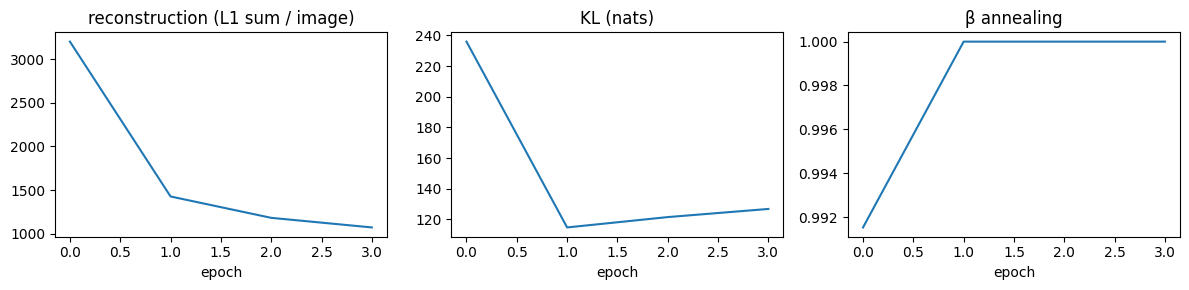

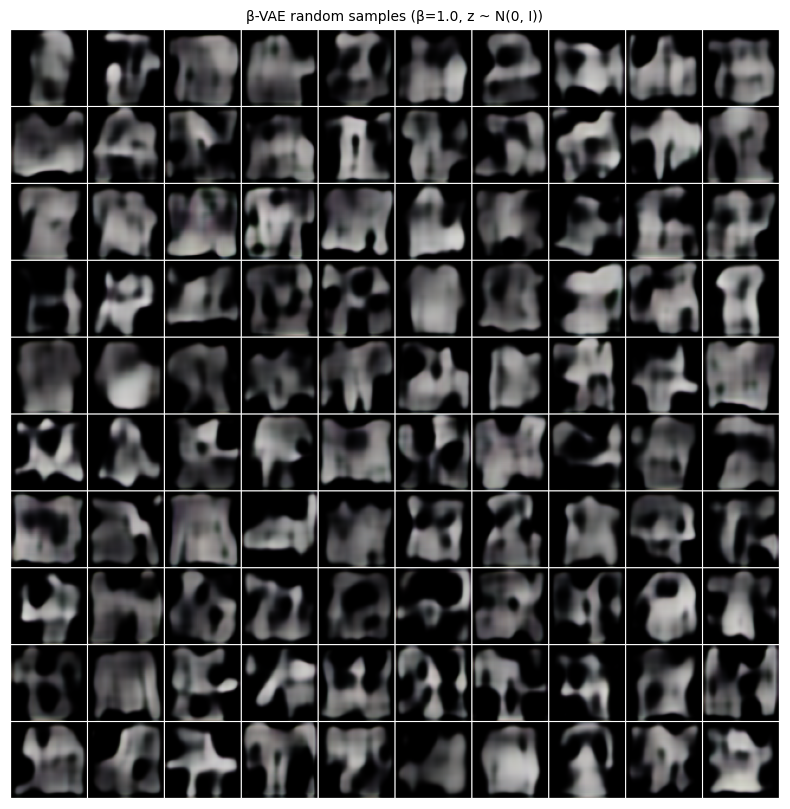

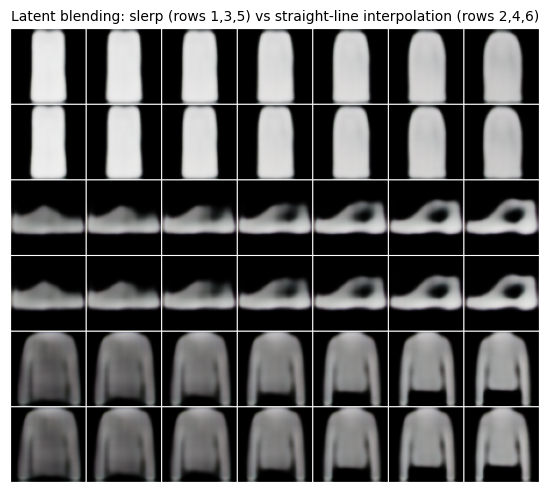

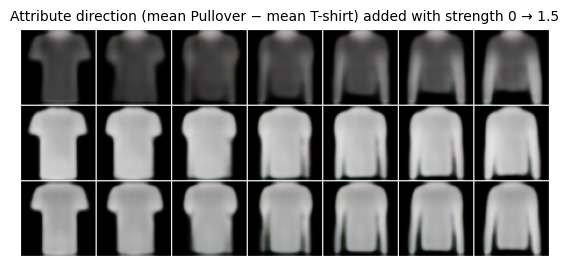

In [6]:
# ============================ 4. β-VAE (Section 7) ============================
@torch.no_grad()
def vae_kl_stats(model, X=None, Y=None):
    X, Y = (Xval, Yval) if X is None else (X, Y)
    model.eval(); mus, lvs = [], []
    for xb, _ in batches(X, Y, 500, shuffle=False):
        mu, lv = model.encode(prep(xb)); mus.append(mu.float()); lvs.append(lv.float())
    mu, lv = torch.cat(mus), torch.cat(lvs)
    kl_dim = (-0.5 * (1 + lv - mu ** 2 - lv.exp())).mean(0)
    return kl_dim.cpu().numpy()

@torch.no_grad()
def vae_sample(model, n, bs=500, z=None):
    model.eval(); out = []
    for i in range(0, n, bs):
        m = min(bs, n - i)
        zz = torch.randn(m, CFG["vae"]["z"], device=DEVICE) if z is None else z[i:i + m].to(DEVICE)
        out.append(model.decode(zz).half().cpu())
    return torch.cat(out)

def train_vae(epochs, beta_max, free_bits=0.0, verbose=True):
    set_seed(); c = CFG["vae"]
    model = ConvVAE(c["z"]).to(DEVICE)
    spe = math.ceil(len(Xtr) / c["batch"])
    opt = torch.optim.AdamW(model.parameters(), lr=c["lr"], weight_decay=c["wd"])
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=max(1, epochs * spe))
    scaler = torch.amp.GradScaler("cuda", enabled=AMP)
    warm_steps = min(c["warm_epochs"], max(1, epochs // 4)) * spe          # ~10 epochs at full length
    hist, step, t0 = dict(recon=[], kl=[], beta=[], val_l1=[]), 0, time.time()
    for ep in range(1, epochs + 1):
        model.train(); rs = torch.zeros((), device=DEVICE); ks = torch.zeros((), device=DEVICE); n = 0
        for xb, yb in batches(Xtr, Ytr, c["batch"]):
            x = augment_ae(prep(xb), yb)
            beta = beta_schedule(step, warm_steps, beta_max)
            with torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=AMP):
                xh, mu, lv = model(x)
            loss, rec, kl = vae_loss(xh.float(), x, mu.float(), lv.float(), beta, free_bits)
            opt.zero_grad(set_to_none=True); scaler.scale(loss).backward(); scaler.step(opt); scaler.update(); sched.step()
            rs += rec; ks += kl; n += 1; step += 1
        rs, ks = rs.item(), ks.item()
        r = eval_recon(model, Xval, Yval, vae=True)
        hist["recon"].append(rs / n); hist["kl"].append(ks / n); hist["beta"].append(beta); hist["val_l1"].append(r["l1"])
        if verbose: print(f"  VAE(β={beta_max}) ep {ep:3d}/{epochs}  recon/img {rs/n:8.1f}  KL {ks/n:6.2f}  β_t {beta:.2f}  val L1 {r['l1']:.4f}")
    model.eval()
    return model, hist, time.time() - t0

# ---- β sweep (E2): train, then compare reconstruction vs sample quality ----
VAE_RUNS, rows = {}, []
for b in P["sweep"]:
    print(f"Training β-VAE with β_max = {b}")
    m, h, t = train_vae(P["vae"], b, free_bits=CFG["vae"]["free_bits"])
    r = eval_recon(m, Xte, Yte, vae=True)
    kl_dim = vae_kl_stats(m)
    fid = fid_only(vae_sample(m, N_SEL))
    VAE_RUNS[b] = dict(model=m, hist=h, time=t)
    rows.append(dict(beta=b, test_l1=r["l1"], test_psnr=r["psnr"], test_ssim=r["ssim"], fid=fid,
                     active_dims=int((kl_dim > 0.01).sum()), kl_total=float(kl_dim.sum())))
    print(f"  -> β={b}: L1 {r['l1']:.4f} | PSNR {r['psnr']:.2f} | FID {fid:.1f} | active dims {rows[-1]['active_dims']}/{CFG['vae']['z']}")
BEST_BETA = min(rows, key=lambda r_: r_["fid"])["beta"]
VAE, VAE_HIST, TIMES["vae"] = VAE_RUNS[BEST_BETA]["model"], VAE_RUNS[BEST_BETA]["hist"], VAE_RUNS[BEST_BETA]["time"]
RES["vae_sweep"] = rows
RES["vae"] = dict(beta=BEST_BETA, free_bits=CFG["vae"]["free_bits"], train_time_s=TIMES["vae"],
                  params_m=sum(p.numel() for p in VAE.parameters()) / 1e6,
                  **{k: v for k, v in next(r_ for r_ in rows if r_["beta"] == BEST_BETA).items() if k != "beta"})
print("selected β =", BEST_BETA, "(lowest FID of the sweep)")

# ---- class-conditional latent Gaussians (lets the unconditional VAE produce labelled samples for TSTR / comparison) ----
@torch.no_grad()
def fit_class_gaussians(model):
    mu_all = torch.cat([model.encode(prep(xb))[0].float() for xb, _ in batches(Xtr, Ytr, 500, shuffle=False)])
    stats = []
    for c in range(10):
        zc = mu_all[Ytr == c]; mean = zc.mean(0)
        cov = torch.cov(zc.T) + 1e-4 * torch.eye(zc.size(1), device=zc.device)
        stats.append((mean, torch.linalg.cholesky(cov)))
    return stats, mu_all
VAE_CLS, MU_TR = fit_class_gaussians(VAE)

@torch.no_grad()
def vae_sample_cc(n):
    labels = BAL_LABELS(n); z = torch.zeros(n, CFG["vae"]["z"], device=DEVICE)
    for c in range(10):
        m_ = (labels == c).to(DEVICE); k = int(m_.sum())
        mean, L = VAE_CLS[c]
        z[m_] = mean + torch.randn(k, mean.numel(), device=DEVICE) @ L.T
    return vae_sample(VAE, n, z=z), labels

# ---- figures ----
fig, ax = plt.subplots(1, 3, figsize=(12, 3))
ax[0].plot(VAE_HIST["recon"]); ax[0].set_title("reconstruction (L1 sum / image)"); ax[1].plot(VAE_HIST["kl"]); ax[1].set_title("KL (nats)")
ax[2].plot(VAE_HIST["beta"]); ax[2].set_title("β annealing")
for a in ax: a.set_xlabel("epoch")
plt.tight_layout(); plt.savefig(f"{FIG}/fig_vae_curves.png", dpi=160); plt.show()
grid_fig(vae_sample(VAE, 100)[:100], 10, f"β-VAE random samples (β={BEST_BETA}, z ~ N(0, I))", f"{FIG}/fig_vae_samples.png")

with torch.no_grad():
    pairs = [(0, 3), (7, 9), (2, 4)]                                  # T-shirt→Dress, Sneaker→Ankle boot, Pullover→Coat
    ts = torch.linspace(0, 1, 7); strips = []
    for ca, cb in pairs:
        ia, ib = (Yte == ca).nonzero()[1].item(), (Yte == cb).nonzero()[1].item()
        mu, _ = VAE.encode(prep(Xte[[ia, ib]])); z0, z1 = mu[0:1], mu[1:2]
        strips.append(VAE.decode(torch.cat([slerp(z0, z1, float(t)) for t in ts])))
        strips.append(VAE.decode(torch.cat([z0 * (1 - t) + z1 * t for t in ts])))
grid_fig(torch.cat(strips), 7, "Latent blending: slerp (rows 1,3,5) vs straight-line interpolation (rows 2,4,6)", f"{FIG}/fig_slerp.png")

with torch.no_grad():                                                  # attribute direction: Pullover (long sleeves) − T-shirt (short sleeves)
    d = MU_TR[Ytr == 2].mean(0) - MU_TR[Ytr == 0].mean(0)
    rows_ = []
    for k in (3, 11, 25):
        ik = (Yte == 0).nonzero()[k].item(); mu0, _ = VAE.encode(prep(Xte[ik:ik + 1]))
        rows_.append(VAE.decode(torch.cat([mu0 + s * d for s in (0, 0.25, 0.5, 0.75, 1.0, 1.25, 1.5)])))
grid_fig(torch.cat(rows_), 7, "Attribute direction (mean Pullover − mean T-shirt) added with strength 0 → 1.5", f"{FIG}/fig_attr.png")

## 5 · Conditional GAN (Section 8)
Hinge loss · spectral norm · projection discriminator · DiffAugment · EMA · FID-based checkpoint selection.

Training the conditional GAN ...
  GAN ep   5/10  D  1.911  G  0.124  FID  255.72  (best 255.72)
  GAN ep  10/10  D  1.852  G  0.200  FID  158.00  (best 158.00)


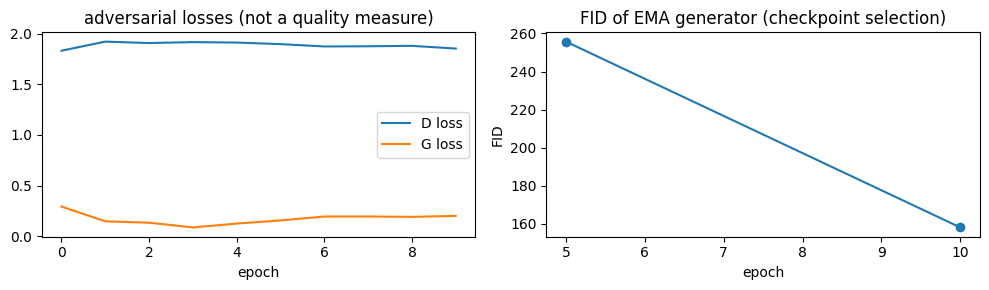

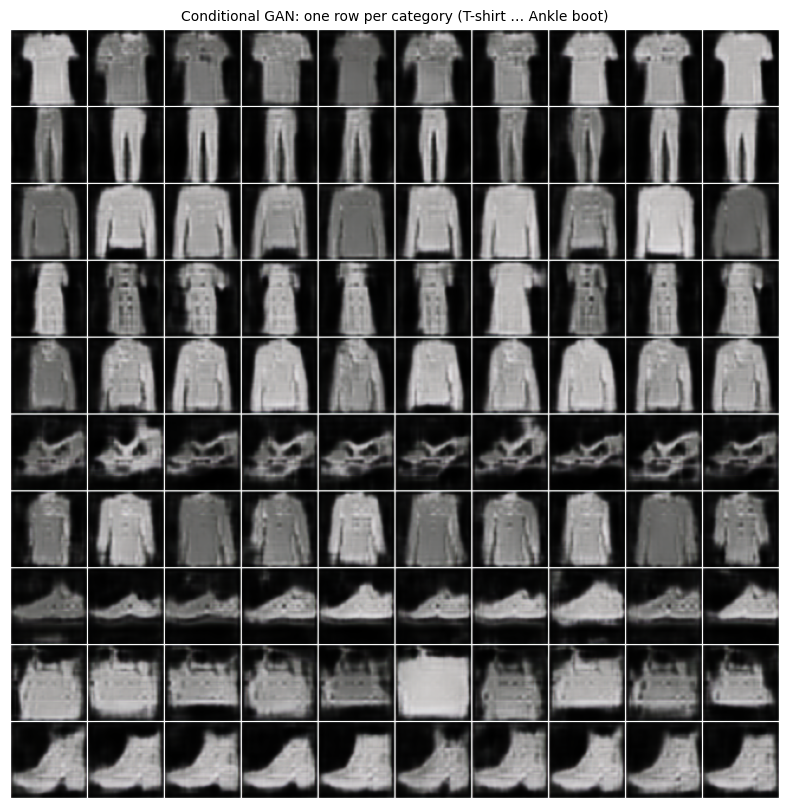

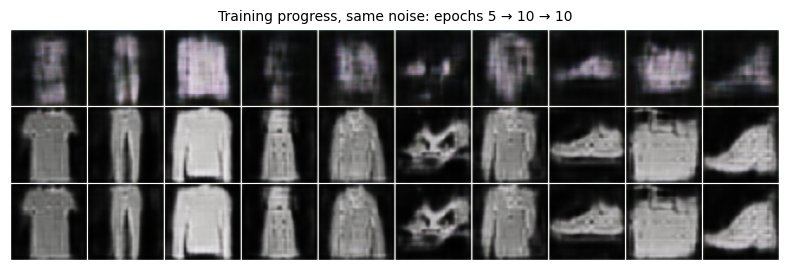

In [7]:
# ============================ 5. CONDITIONAL GAN (Section 8) ============================
@torch.no_grad()
def gan_sample(Gm, n, labels=None, trunc=1.0, bs=500, seed=None):
    Gm.eval(); out = []
    labels = BAL_LABELS(n) if labels is None else labels
    gen = torch.Generator(device=DEVICE).manual_seed(seed) if seed is not None else None
    for i in range(0, n, bs):
        y = labels[i:i + bs].to(DEVICE)
        z = torch.randn(len(y), CFG["gan"]["z"], device=DEVICE, generator=gen) * trunc
        out.append(Gm(z, y).half().cpu())
    return torch.cat(out)

def train_gan(epochs, conditional=True, use_aug=True, use_ema=True, eval_every=5, verbose=True):
    set_seed(); c = CFG["gan"]
    G = Generator(c["z"], 10, c["emb"], c["ch_g"]).to(DEVICE); D = Discriminator(10, c["ch_d"]).to(DEVICE)
    G_ema = copy.deepcopy(G).eval()
    optD = torch.optim.Adam(D.parameters(), lr=c["lr_d"], betas=c["betas"])
    optG = torch.optim.Adam(G.parameters(), lr=c["lr_g"], betas=c["betas"])
    aug = diff_augment if use_aug else (lambda x: x)
    fixed_z = torch.randn(80, c["z"], device=DEVICE); fixed_y = torch.arange(80, device=DEVICE) // 8      # 10 classes x 8 samples
    hist = dict(d=[], g=[], fid_epoch=[], fid=[]); progress = []
    best, t0 = (float("inf"), None), time.time()
    for ep in range(1, epochs + 1):
        G.train(); D.train(); dl = gl = 0.0; nb = 0
        for xb, yb in batches(Xtr, Ytr, c["batch"], drop_last=True):
            real = prep(xb); y = yb if conditional else torch.zeros_like(yb)
            dl += d_step(D, G, real, y, c["z"], optD, aug)
            gl += g_step(D, G, y, c["z"], optG, aug)
            if use_ema: ema_update(G_ema, G, c["ema"])
            nb += 1
        hist["d"].append(dl / nb); hist["g"].append(gl / nb)
        if ep % eval_every == 0 or ep == epochs:
            S = G_ema if use_ema else G
            lab = BAL_LABELS(N_SEL) if conditional else torch.zeros(N_SEL, dtype=torch.long)
            fid = fid_only(gan_sample(S, N_SEL, labels=lab))
            hist["fid_epoch"].append(ep); hist["fid"].append(fid)
            S.eval()
            with torch.no_grad():
                progress.append((ep, S(fixed_z, fixed_y if conditional else torch.zeros_like(fixed_y)).half().cpu()))
            if fid < best[0]:
                best = (fid, copy.deepcopy(S.state_dict()))
            if verbose: print(f"  GAN ep {ep:3d}/{epochs}  D {dl/nb:6.3f}  G {gl/nb:6.3f}  FID {fid:7.2f}  (best {best[0]:.2f})")
    Gbest = Generator(c["z"], 10, c["emb"], c["ch_g"]).to(DEVICE)
    Gbest.load_state_dict(best[1]); Gbest.eval()                    # checkpoint chosen by FID, not by adversarial loss
    return Gbest, hist, time.time() - t0, progress, best[0]

print("Training the conditional GAN ...")
GAN, GAN_HIST, TIMES["gan"], GAN_PROG, GAN_BEST_FID = train_gan(P["gan"], eval_every=P["gan_eval_every"])
RES["gan"] = dict(best_selection_fid=GAN_BEST_FID, train_time_s=TIMES["gan"],
                  params_g_m=sum(p.numel() for p in GAN.parameters()) / 1e6)

# ---- figures ----
fig, ax = plt.subplots(1, 2, figsize=(10, 3))
ax[0].plot(GAN_HIST["d"], label="D loss"); ax[0].plot(GAN_HIST["g"], label="G loss"); ax[0].set_xlabel("epoch"); ax[0].legend(); ax[0].set_title("adversarial losses (not a quality measure)")
ax[1].plot(GAN_HIST["fid_epoch"], GAN_HIST["fid"], "o-"); ax[1].set_xlabel("epoch"); ax[1].set_ylabel("FID"); ax[1].set_title("FID of EMA generator (checkpoint selection)")
plt.tight_layout(); plt.savefig(f"{FIG}/fig_gan_curves.png", dpi=160); plt.show()
grid_fig(gan_sample(GAN, 100, labels=torch.arange(100) // 10, seed=1), 10, "Conditional GAN: one row per category (T-shirt … Ankle boot)", f"{FIG}/fig_gan_classes.png")
sel = [GAN_PROG[0], GAN_PROG[len(GAN_PROG) // 2], GAN_PROG[-1]]
grid_fig(torch.cat([p[1][[0, 8, 16, 24, 32, 40, 48, 56, 64, 72]] for p in sel]), 10,
         "Training progress, same noise: epochs " + " → ".join(str(p[0]) for p in sel), f"{FIG}/fig_gan_progress.png")

## 6 · Evaluation suite, TSTR, memorisation, ablations (Sections 9 & 11)
Includes experiments E3–E5 and the blind human-evaluation sheet.

Evaluating on 2000 generated samples per model; reference = 2000 real test images
[cGAN (EMA)] FID 157.57 | KID 0.1374 | P 0.062 R 0.001 | div 0.133 | near-copy 0.45%
[β-VAE (prior)] FID 170.18 | KID 0.1637 | P 0.108 R 0.000 | div 0.281 | near-copy 0.00%
real test images: diversity 0.273, flagged as near-copy 0.95% (control)
TSTR accuracy on real test set: {'gan': 0.3996, 'vae': 0.4558, 'real_baseline': 0.4141}


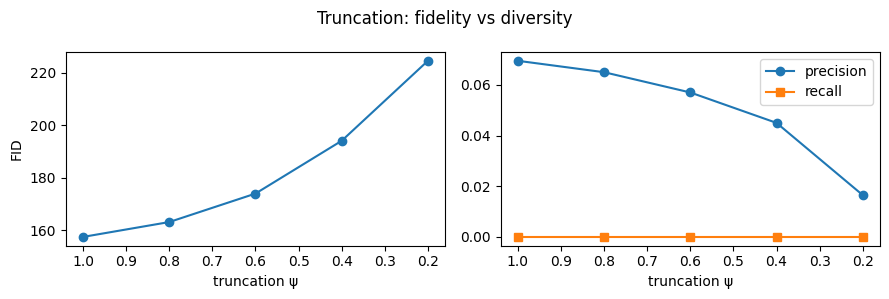

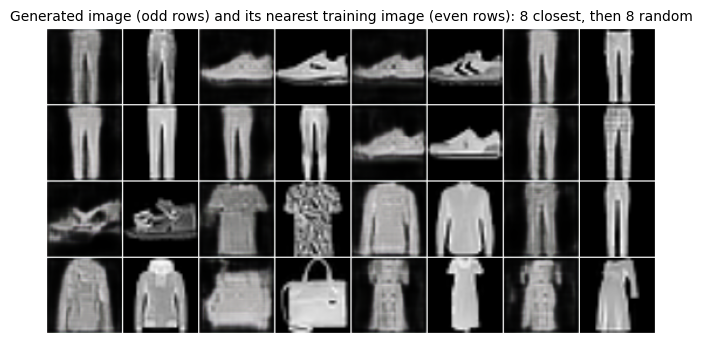

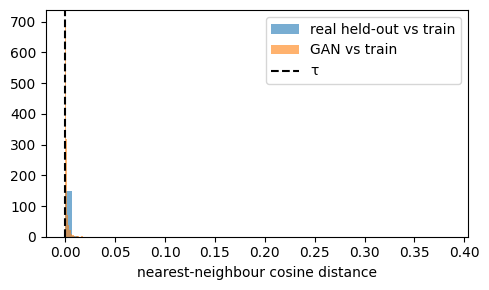

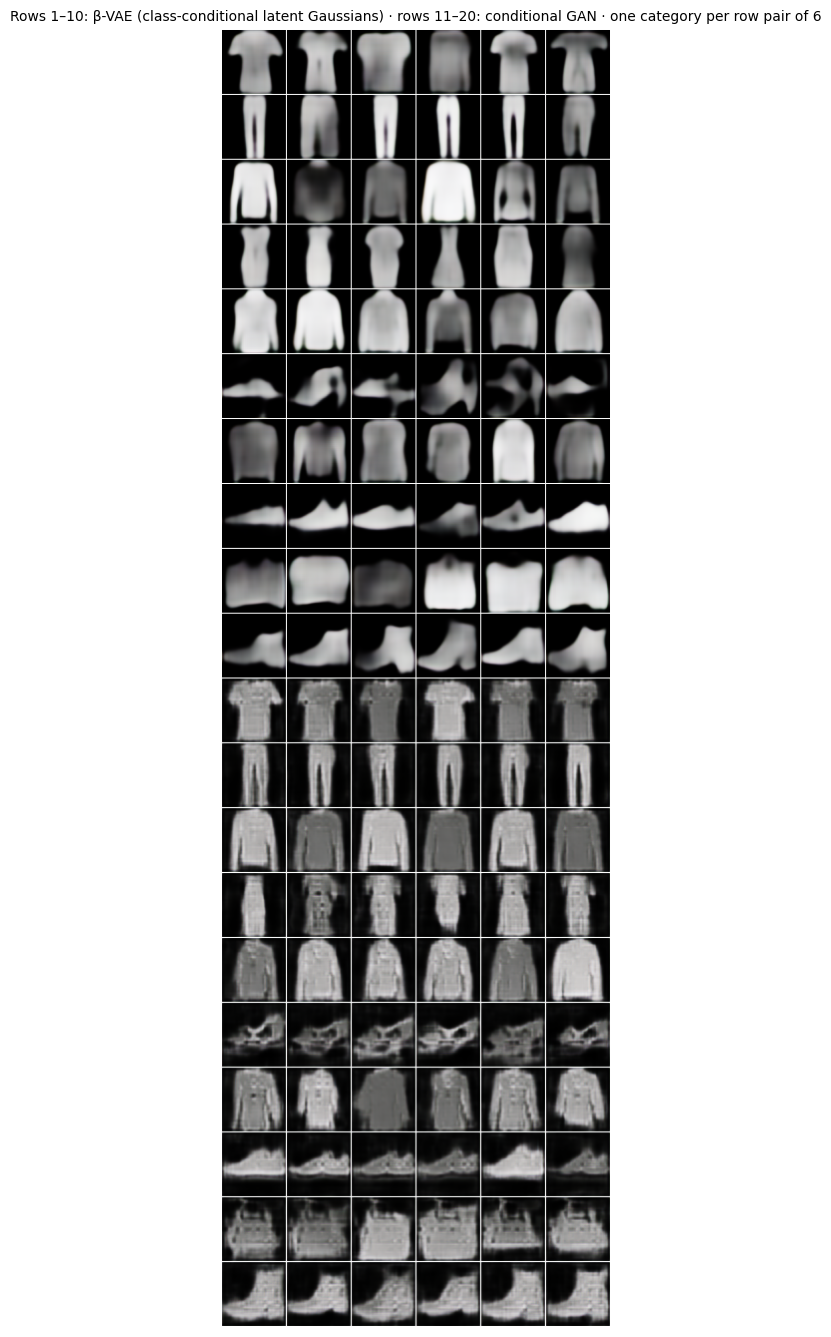

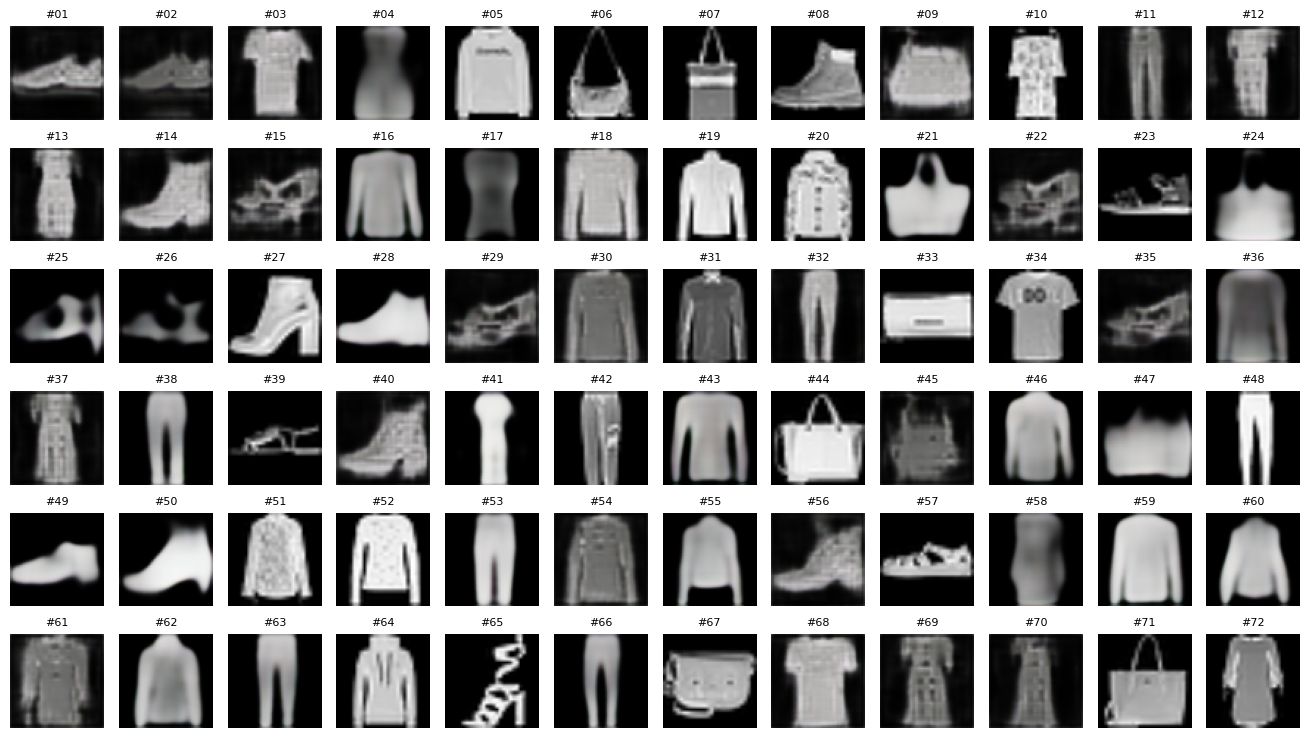

Human-evaluation sheet saved to styleforge_outputs/human_eval/ (sheet.png, key.csv, score_sheet.csv); fleiss_kappa() is ready for the filled sheet.


In [8]:
# ============================ 6. SHARED EVALUATION SUITE (Section 11) ============================
N_GEN = P["n_gen"]
GAN_IMGS = gan_sample(GAN, N_GEN, seed=123)                         # balanced over the 10 categories
GAN_LAB = BAL_LABELS(N_GEN)
VAE_IMGS = vae_sample(VAE, N_GEN)                                   # unconditional, z ~ N(0, I)
VAE_CC_IMGS, VAE_CC_LAB = vae_sample_cc(N_GEN)                      # class-conditional latent Gaussians (labelled)

print("Evaluating on", N_GEN, "generated samples per model; reference =", REF_N, "real test images")
RES["gan_eval"] = eval_generative("cGAN (EMA)", GAN_IMGS, GAN_LAB)
RES["vae_eval"] = eval_generative("β-VAE (prior)", VAE_IMGS)
RES["real_ref"] = dict(diversity=diversity(REAL_REF, Yte[:REF_N].cpu()), note="diversity of real test images, for context")
_dn, _ = nn_info(REAL_REF[:2000]); RES["real_ref"]["near_copy_rate_test"] = float((_dn < TAU).mean())
print(f"real test images: diversity {RES['real_ref']['diversity']:.3f}, flagged as near-copy {100*RES['real_ref']['near_copy_rate_test']:.2f}% (control)")

# ---- TSTR: train on synthetic only, test on real ----
class SmallCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(nn.Conv2d(3, 32, 3, 2, 1), nn.ReLU(), nn.Conv2d(32, 64, 3, 2, 1), nn.ReLU(),
                                 nn.Conv2d(64, 128, 3, 2, 1), nn.ReLU(), nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Linear(128, 10))
    def forward(self, x): return self.net(x)

def tstr_accuracy(imgs, labels, epochs=3):
    set_seed(); clf = SmallCNN().to(DEVICE); opt = torch.optim.Adam(clf.parameters(), 1e-3)
    imgs, labels = imgs.to(DEVICE), labels.to(DEVICE)
    for _ in range(epochs):
        clf.train(); perm_ = torch.randperm(len(imgs), device=DEVICE)
        for i in range(0, len(imgs), 128):
            j = perm_[i:i + 128]
            loss = F.cross_entropy(clf(imgs[j].float()), labels[j]); opt.zero_grad(); loss.backward(); opt.step()
    clf.eval(); correct = 0
    with torch.no_grad():
        for xb, yb in batches(Xte, Yte, 500, shuffle=False):
            correct += (clf(prep(xb)).argmax(1) == yb).sum().item()
    return correct / len(Xte)

n_t = min(N_GEN, 10000)
real_sub = torch.cat([prep(Xtr[i:i + 500]).half() for i in range(0, n_t, 500)])
RES["tstr"] = dict(gan=tstr_accuracy(GAN_IMGS[:n_t], GAN_LAB[:n_t]), vae=tstr_accuracy(VAE_CC_IMGS[:n_t], VAE_CC_LAB[:n_t]),
                   real_baseline=tstr_accuracy(real_sub, Ytr[:n_t]), n=n_t)
RES["gan_eval"]["tstr"], RES["vae_eval"]["tstr"] = RES["tstr"]["gan"], RES["tstr"]["vae"]
RES["vae_eval"]["diversity_cc"] = diversity(VAE_CC_IMGS, VAE_CC_LAB)
print("TSTR accuracy on real test set:", {k: round(v, 4) for k, v in RES["tstr"].items() if k != "n"})

# ---- fidelity–variety trade-off via truncation ----
trunc_rows = []
for tr_ in (1.0, 0.8, 0.6, 0.4, 0.2):
    im = gan_sample(GAN, N_SEL, trunc=tr_, seed=7); f_ = feats(im); p_, r_ = prec_recall(F_REAL, f_)
    trunc_rows.append(dict(trunc=tr_, fid=fid_from_feats(f_, REF), precision=p_, recall=r_))
RES["truncation"] = trunc_rows
fig, ax = plt.subplots(1, 2, figsize=(9, 3))
ax[0].plot([r_["trunc"] for r_ in trunc_rows], [r_["fid"] for r_ in trunc_rows], "o-"); ax[0].set_xlabel("truncation ψ"); ax[0].set_ylabel("FID"); ax[0].invert_xaxis()
ax[1].plot([r_["trunc"] for r_ in trunc_rows], [r_["precision"] for r_ in trunc_rows], "o-", label="precision")
ax[1].plot([r_["trunc"] for r_ in trunc_rows], [r_["recall"] for r_ in trunc_rows], "s-", label="recall"); ax[1].set_xlabel("truncation ψ"); ax[1].invert_xaxis(); ax[1].legend()
plt.suptitle("Truncation: fidelity vs diversity"); plt.tight_layout(); plt.savefig(f"{FIG}/fig_truncation.png", dpi=160); plt.show()

# ---- near-copy check: generated image vs its nearest training image ----
d_g, ix_g = nn_info(GAN_IMGS[:2000])
order = np.argsort(d_g)[:8]; rand = np.random.RandomState(0).choice(len(d_g), 8, replace=False)
pairs_ = []
for i in list(order) + list(rand):
    j_ = int(ix_g[i]); pairs_ += [GAN_IMGS[i].float(), prep(Xtr[j_:j_ + 1])[0].cpu()]
grid_fig(torch.stack(pairs_), 8, "Generated image (odd rows) and its nearest training image (even rows): 8 closest, then 8 random", f"{FIG}/fig_copy_check.png")
plt.figure(figsize=(5, 3)); plt.hist(D_VAL, 60, alpha=.6, density=True, label="real held-out vs train")
plt.hist(d_g, 60, alpha=.6, density=True, label="GAN vs train"); plt.axvline(TAU, color="k", ls="--", label="τ")
plt.xlabel("nearest-neighbour cosine distance"); plt.legend(); plt.tight_layout(); plt.savefig(f"{FIG}/fig_nn_hist.png", dpi=160); plt.show()

# ---- side-by-side comparison, one row per category ----
cmp_lab = torch.arange(60) // 6
grid_fig(torch.cat([VAE_CC_IMGS[[i for c in range(10) for i in (VAE_CC_LAB == c).nonzero()[:6].flatten().tolist()]].float(),
                    gan_sample(GAN, 60, labels=cmp_lab, seed=5).float()]), 6,
         "Rows 1–10: β-VAE (class-conditional latent Gaussians) · rows 11–20: conditional GAN · one category per row pair of 6", f"{FIG}/fig_compare.png", scale=0.7)

# ---- E3 / E4 / E5 (short runs, identical budget per variant) ----
if RUN_ABLATIONS:
    ab = P["abl"]; print(f"Ablations at {ab} epochs per variant")
    e3 = {}
    for name, fb in (("free_bits = 0", 0.0), (f"free_bits = {CFG['vae']['free_bits']}", CFG["vae"]["free_bits"])):
        m, _, _ = train_vae(ab, BEST_BETA, free_bits=fb, verbose=False); kd = vae_kl_stats(m)
        e3[name] = dict(active_dims=int((kd > 0.01).sum()), kl_total=float(kd.sum()), fid=fid_only(vae_sample(m, N_SEL)))
        del m
    RES["E3"] = dict(epochs=ab, rows=e3); print("E3", e3)
    e5 = {}
    for name, kw in (("conditional + DiffAug + EMA (baseline)", {}), ("unconditional (E4)", dict(conditional=False)),
                     ("no DiffAugment", dict(use_aug=False)), ("no EMA", dict(use_ema=False))):
        Gm, h_, _, _, bf = train_gan(ab, eval_every=ab, verbose=False, **kw)
        e5[name] = dict(fid=bf)
        if kw.get("conditional", True):
            im = gan_sample(Gm, N_SEL); f_ = feats(im); p_, r_ = prec_recall(F_REAL, f_)
            e5[name].update(kid=kid_from_feats(F_REAL, f_)[0], precision=p_, recall=r_)
        del Gm
        print(f"  {name}: {e5[name]}")
    RES["E5"] = dict(epochs=ab, rows=e5)

# ---- human-evaluation material (Section 11.4): blind, shuffled, ID-only sheet + answer key ----
import csv
def make_human_eval(n_each=24, seed=11):
    rng = np.random.RandomState(seed)
    pool = [("real", REAL_REF[i].float()) for i in rng.choice(len(REAL_REF), n_each, replace=False)] + \
           [("vae", VAE_CC_IMGS[i].float()) for i in rng.choice(len(VAE_CC_IMGS), n_each, replace=False)] + \
           [("gan", GAN_IMGS[i].float()) for i in rng.choice(len(GAN_IMGS), n_each, replace=False)]
    order_ = rng.permutation(len(pool)); os.makedirs(f"{OUT}/human_eval", exist_ok=True)
    cols = 12; rows_n = math.ceil(len(pool) / cols)
    fig, axs = plt.subplots(rows_n, cols, figsize=(cols * 1.1, rows_n * 1.25))
    for a in axs.flat: a.axis("off")
    with open(f"{OUT}/human_eval/key.csv", "w", newline="") as fk, open(f"{OUT}/human_eval/score_sheet.csv", "w", newline="") as fs:
        wk, ws = csv.writer(fk), csv.writer(fs); wk.writerow(["id", "source"]); ws.writerow(["id", "rater", "realism_1to5", "category_fidelity_1to5", "novelty_1to5", "ideation_usefulness_1to5"])
        for k, o in enumerate(order_):
            src, im = pool[o]; a = axs.flat[k]
            a.imshow(((im.permute(1, 2, 0) + 1) / 2).clamp(0, 1).numpy()); a.set_title(f"#{k+1:02d}", fontsize=8); wk.writerow([k + 1, src])
            for rater in ("R1", "R2", "R3"): ws.writerow([k + 1, rater, "", "", "", ""])
    plt.tight_layout(); plt.savefig(f"{OUT}/human_eval/sheet.png", dpi=150); plt.show()

def fleiss_kappa(table):
    """table: (items x categories) counts of raters per category; call after reviewers fill score_sheet.csv."""
    t = np.asarray(table, float); n = t.sum(1)[0]; N = len(t)
    p_j = t.sum(0) / (N * n); P_i = ((t ** 2).sum(1) - n) / (n * (n - 1))
    return (P_i.mean() - (p_j ** 2).sum()) / (1 - (p_j ** 2).sum())
make_human_eval()
print("Human-evaluation sheet saved to", f"{OUT}/human_eval/ (sheet.png, key.csv, score_sheet.csv); fleiss_kappa() is ready for the filled sheet.")

## 7 · Platform: FastAPI inference service (Section 12)
Written to `styleforge/service/main.py`; the next cell registers the checkpoints and tests it.

In [9]:
%%writefile styleforge/service/main.py
"""StyleForge inference API.   Run:  uvicorn styleforge.service.main:app --host 0.0.0.0 --port 8000"""
import base64, io, json, os, time
from typing import List, Optional

import numpy as np
import torch
from fastapi import FastAPI, HTTPException
from PIL import Image
from pydantic import BaseModel, Field
from torchvision.transforms.functional import to_pil_image

from styleforge.models import CLASSES, ConvAutoencoder, ConvVAE, Generator, prep, slerp

ART = os.environ.get("STYLEFORGE_ART", "styleforge/artifacts")
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
app = FastAPI(title="StyleForge API", version="1.0")


def _load(name, cls):
    ck = torch.load(f"{ART}/{name}.pt", map_location="cpu", weights_only=False)
    model = cls(**ck["init_kwargs"])
    model.load_state_dict(ck["state_dict"])
    return model.to(DEVICE).eval(), ck


# weights are loaded once at start-up (EMA / best-FID generator, VAE, AE encoder)
GENERATOR, GEN_CK = _load("gan_ema", Generator)
VAE, VAE_CK = _load("vae", ConvVAE)
AE, AE_CK = _load("ae", ConvAutoencoder)
CAT_X = np.load(f"{ART}/catalog_x.npy")                                   # uint8 (N,28,28) licensed catalogue
CAT_Y = np.load(f"{ART}/catalog_y.npy")
CAT_EMB = torch.from_numpy(np.load(f"{ART}/catalog_emb.npy")).to(DEVICE)   # L2-normalised AE embeddings
Z_DIM = GEN_CK["init_kwargs"]["z_dim"]
MODEL_VERSION = GEN_CK.get("version", "gan-1")


def _png_b64(img01):
    buf = io.BytesIO()
    to_pil_image(img01.cpu().clamp(0, 1)).save(buf, format="PNG")
    return base64.b64encode(buf.getvalue()).decode()


def _to01(x):
    return (x + 1) / 2


class GenerateRequest(BaseModel):
    category: str
    count: int = Field(4, ge=1, le=16)
    seed: Optional[int] = None
    truncation: float = Field(1.0, gt=0.0, le=1.0)


class BlendRequest(BaseModel):
    id_a: int = Field(ge=0)
    id_b: int = Field(ge=0)
    steps: int = Field(7, ge=2, le=16)


class SimilarRequest(BaseModel):
    image_id: Optional[int] = None
    image_b64: Optional[str] = None
    k: int = Field(8, ge=1, le=32)


class FeedbackRequest(BaseModel):
    category: str
    seed: int
    model_version: str
    accepted: bool


@app.post("/v1/generate")
def generate(req: GenerateRequest):
    if req.category not in CLASSES:
        raise HTTPException(status_code=422, detail="Unknown category")
    g = torch.Generator(device=DEVICE)                                    # per-request RNG, no global state
    g.manual_seed(req.seed) if req.seed is not None else g.seed()
    z = torch.randn(req.count, Z_DIM, device=DEVICE, generator=g) * req.truncation
    y = torch.full((req.count,), CLASSES.index(req.category), device=DEVICE)
    with torch.inference_mode():
        imgs = _to01(GENERATOR(z, y))
    return {"model_version": MODEL_VERSION, "seed": g.initial_seed(), "category": req.category,
            "synthetic": True, "images": [_png_b64(im) for im in imgs]}


@app.post("/v1/blend")
def blend(req: BlendRequest):
    n = len(CAT_X)
    if req.id_a >= n or req.id_b >= n:
        raise HTTPException(status_code=422, detail="Unknown image id")
    with torch.inference_mode():
        mu, _ = VAE.encode(prep(torch.from_numpy(CAT_X[[req.id_a, req.id_b]]).to(DEVICE)))
        frames = [VAE.decode(slerp(mu[0:1], mu[1:2], float(t)))[0] for t in torch.linspace(0, 1, req.steps)]
    return {"model_version": VAE_CK.get("version", "vae-1"), "synthetic": True, "steps": req.steps,
            "images": [_png_b64(_to01(f)) for f in frames]}


@app.post("/v1/similar")
def similar(req: SimilarRequest):
    if req.image_id is not None:
        if not 0 <= req.image_id < len(CAT_X):
            raise HTTPException(status_code=422, detail="Unknown image id")
        arr = CAT_X[req.image_id]
    elif req.image_b64:
        try:
            arr = np.array(Image.open(io.BytesIO(base64.b64decode(req.image_b64))).convert("L").resize((28, 28)))
        except Exception:
            raise HTTPException(status_code=422, detail="Could not decode image")
    else:
        raise HTTPException(status_code=422, detail="Provide image_id or image_b64")
    with torch.inference_mode():
        z = torch.nn.functional.normalize(AE.encode(prep(torch.from_numpy(arr[None]).to(DEVICE))), dim=1)
        sims, idx = (CAT_EMB @ z[0]).topk(req.k)
    return {"results": [{"id": int(i), "category": CLASSES[int(CAT_Y[int(i)])], "similarity": float(s)}
                        for s, i in zip(sims.cpu(), idx.cpu())]}


@app.post("/v1/feedback")
def feedback(req: FeedbackRequest):
    with open(f"{ART}/feedback.jsonl", "a") as f:
        f.write(json.dumps({**req.dict(), "ts": time.time()}) + "\n")
    return {"status": "recorded"}


@app.get("/v1/models")
def models():
    reg = json.load(open(f"{ART}/registry.json")) if os.path.exists(f"{ART}/registry.json") else {}
    return {"models": reg}


@app.get("/healthz")
def healthz():
    return {"status": "ok", "device": str(DEVICE)}

Writing styleforge/service/main.py


## 7b · Registry, packaging, latency and a live self-test of the API

registry: {'ae': {'stage': 'production', 'version': 'ae-fast-1'}, 'vae': {'stage': 'production', 'version': 'vae-fast-1'}, 'gan_ema': {'stage': 'production', 'version': 'gan_ema-fast-1'}} | release gate passed: True
latency (ms, batch of 4): {'gan': {'p50': 1.96, 'p95': 2.05}, 'vae': {'p50': 4.06, 'p95': 4.25}, 'ae': {'p50': 1.95, 'p95': 2.17}}
API self-test: {'POST /v1/generate': 200, 'POST /v1/blend': 200, 'POST /v1/similar': 200, 'POST /v1/feedback': 200, 'invalid category (expect 422)': 422, 'GET /healthz': 200, 'same seed -> same images': True}


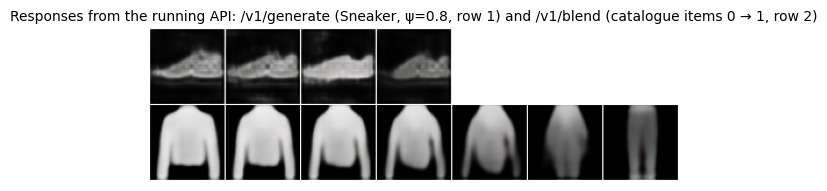

In [10]:
# ============================ 7. REGISTRY, PACKAGING & SERVICE TEST (Sections 12–14) ============================
# ---- model registry: every checkpoint stores config, seed, dataset version, metrics ----
gate_gan_beats_vae = RES["gan_eval"]["fid"] < RES["vae_eval"]["fid"]            # release gate from Section 11.5
def save_ckpt(name, model, init_kwargs, cfg, metrics, stage):
    torch.save(dict(state_dict={k: v.cpu() for k, v in model.state_dict().items()}, init_kwargs=init_kwargs, config=cfg,
                    seed=SEED, dataset_version=DATASET_VERSION, metrics=metrics, version=f"{name}-{MODE}-1", stage=stage,
                    torch=torch.__version__, gpu=GPU_NAME), f"{ART}/{name}.pt")
    return dict(file=f"{name}.pt", stage=stage, version=f"{name}-{MODE}-1", metrics=metrics)

c = CFG
REGISTRY = {
    "ae":      save_ckpt("ae",  AE,  dict(z_dim=c["ae"]["z"]), c["ae"], {k: RES["ae"][k] for k in ("test_l1", "test_psnr", "test_ssim")}, "production"),
    "vae":     save_ckpt("vae", VAE, dict(z_dim=c["vae"]["z"]), {**c["vae"], "beta": BEST_BETA}, {k: RES["vae"][k] for k in ("test_l1", "test_ssim", "fid")}, "production"),
    "gan_ema": save_ckpt("gan_ema", GAN, dict(z_dim=c["gan"]["z"], n_classes=10, emb_dim=c["gan"]["emb"], ch=c["gan"]["ch_g"]), c["gan"],
                         {"fid": RES["gan_eval"]["fid"], "kid": RES["gan_eval"]["kid"]}, "production" if gate_gan_beats_vae else "staging"),
}
json.dump(REGISTRY, open(f"{ART}/registry.json", "w"), indent=2)
np.save(f"{ART}/catalog_x.npy", Xtr.cpu().numpy()); np.save(f"{ART}/catalog_y.npy", Ytr.cpu().numpy())
np.save(f"{ART}/catalog_emb.npy", Z_TRN.cpu().numpy().astype("float32"))
RES["registry"] = {k: dict(stage=v["stage"], version=v["version"]) for k, v in REGISTRY.items()}
RES["release_gate"] = dict(rule="cGAN FID < β-VAE FID (same protocol)", passed=bool(gate_gan_beats_vae))
print("registry:", RES["registry"], "| release gate passed:", gate_gan_beats_vae)

# ---- Dockerfile + requirements ----
open("styleforge/service/Dockerfile", "w").write("""FROM pytorch/pytorch:2.4.0-cuda12.1-cudnn9-runtime
WORKDIR /app
COPY requirements.txt .
RUN pip install --no-cache-dir -r requirements.txt
COPY styleforge/ styleforge/
EXPOSE 8000
CMD ["uvicorn", "styleforge.service.main:app", "--host", "0.0.0.0", "--port", "8000"]
""")
open("requirements.txt", "w").write("fastapi\nuvicorn\npydantic\npillow\nnumpy\ntorchvision\n")

# ---- measured latency (batch of 4), p50 / p95 over 30 calls ----
def timeit(fn, n=30):
    fn(); ts = []
    for _ in range(n):
        if AMP: torch.cuda.synchronize()
        t0 = time.perf_counter(); fn()
        if AMP: torch.cuda.synchronize()
        ts.append((time.perf_counter() - t0) * 1000)
    return dict(p50=float(np.percentile(ts, 50)), p95=float(np.percentile(ts, 95)))
_y4 = torch.arange(4, device=DEVICE); _z4 = torch.randn(4, CFG["gan"]["z"], device=DEVICE)
_x4 = prep(Xte[:4]); _lat_vae = torch.randn(4, CFG["vae"]["z"], device=DEVICE)
with torch.inference_mode():
    RES["latency_ms"] = dict(
        gan=timeit(lambda: GAN(_z4, _y4)),
        vae=timeit(lambda: VAE.decode(slerp(_lat_vae[0:1].expand(4, -1), _lat_vae[1:2].expand(4, -1), 0.5))),
        ae=timeit(lambda: AE.encode(_x4)))
print("latency (ms, batch of 4):", {k: {a: round(b, 2) for a, b in v.items()} for k, v in RES["latency_ms"].items()})

# ---- exercise the real FastAPI app in-process ----
import io, base64
from PIL import Image
os.environ["STYLEFORGE_ART"] = ART
RES["api_test"] = {}
try:
    from fastapi.testclient import TestClient
    for m_ in [k for k in sys.modules if k.startswith("styleforge.service")]: del sys.modules[m_]
    service = importlib.import_module("styleforge.service.main")
    client = TestClient(service.app)
    r1 = client.post("/v1/generate", json=dict(category="Sneaker", count=4, seed=3, truncation=0.8))
    r2 = client.post("/v1/blend", json=dict(id_a=0, id_b=1, steps=7))
    r3 = client.post("/v1/similar", json=dict(image_id=5, k=5))
    r4 = client.post("/v1/feedback", json=dict(category="Sneaker", seed=3, model_version=REGISTRY["gan_ema"]["version"], accepted=True))
    r5 = client.post("/v1/generate", json=dict(category="Spaceship"))
    r6 = client.get("/healthz")
    RES["api_test"] = {"POST /v1/generate": r1.status_code, "POST /v1/blend": r2.status_code, "POST /v1/similar": r3.status_code,
                       "POST /v1/feedback": r4.status_code, "invalid category (expect 422)": r5.status_code, "GET /healthz": r6.status_code}
    same = client.post("/v1/generate", json=dict(category="Sneaker", count=4, seed=3, truncation=0.8)).json()["images"] == r1.json()["images"]
    RES["api_test"]["same seed -> same images"] = bool(same)
    print("API self-test:", RES["api_test"])
    imgs_api = [torch.from_numpy(np.array(Image.open(io.BytesIO(base64.b64decode(b))).convert("RGB"))).permute(2, 0, 1).float() / 127.5 - 1
                for b in r1.json()["images"] + r2.json()["images"]]
    grid_fig(torch.stack(imgs_api[:4] + [torch.ones(3, 64, 64)] * 3 + imgs_api[4:]), 7,
             "Responses from the running API: /v1/generate (Sneaker, ψ=0.8, row 1) and /v1/blend (catalogue items 0 → 1, row 2)", f"{FIG}/fig_api.png")
except Exception as e:
    print("API self-test skipped:", type(e).__name__, e)

## 8 · Cost model and architecture figure (Sections 4 & 14)

t_gen = 0.490 ms/image | variable cost per accepted asset = $0.0667 | break-even N* = 75 assets (u=0.5)


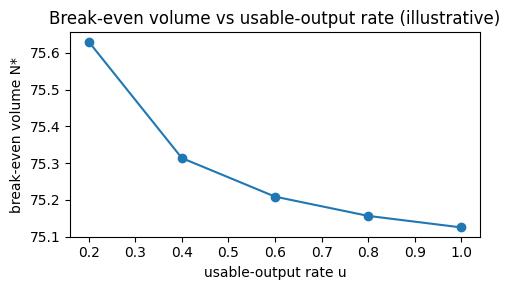

results saved -> styleforge_outputs/results.json


In [11]:
# ============================ 8. COST MODEL (Section 14.3) ============================
# t_gen is MEASURED from this run; the money figures are ILLUSTRATIVE ASSUMPTIONS - replace them with the company's real numbers.
ASSUME = dict(C_trad=20.0,      # USD per conventionally produced asset (photo shoot / manual mock-up)
              C_train=1500.0,   # USD one-off training + engineering cost
              gpu_hour=1.50,    # USD per GPU hour
              t_rev=10.0,       # seconds of reviewer time per generated image
              rev_hour=12.0,    # USD per reviewer hour
              u=0.5)            # usable-output rate (needs real reviewer feedback; 0.5 is a placeholder)
t_gen = RES["latency_ms"]["gan"]["p50"] / 1000 / 4                     # GPU seconds per image (batch of 4)
c_gpu, c_rev = ASSUME["gpu_hour"] / 3600, ASSUME["rev_hour"] / 3600
def cost_per_accepted(N, u): return ASSUME["C_train"] / (N * u) + (t_gen * c_gpu + ASSUME["t_rev"] * c_rev) / u
def breakeven(u):
    per_asset = (t_gen * c_gpu + ASSUME["t_rev"] * c_rev) / u
    return ASSUME["C_train"] / (ASSUME["C_trad"] - per_asset) if ASSUME["C_trad"] > per_asset else float("inf")
RES["cost"] = dict(assumptions=ASSUME, t_gen_s=t_gen, per_accepted_asset_variable=(t_gen * c_gpu + ASSUME["t_rev"] * c_rev) / ASSUME["u"],
                   break_even_N=breakeven(ASSUME["u"]), sensitivity={str(u): breakeven(u) for u in (0.2, 0.4, 0.6, 0.8, 1.0)})
print(f"t_gen = {t_gen*1000:.3f} ms/image | variable cost per accepted asset = ${RES['cost']['per_accepted_asset_variable']:.4f} | break-even N* = {RES['cost']['break_even_N']:.0f} assets (u={ASSUME['u']})")
us = np.array(list(RES["cost"]["sensitivity"].keys()), float); ns = np.array(list(RES["cost"]["sensitivity"].values()))
plt.figure(figsize=(5, 3)); plt.plot(us, ns, "o-"); plt.xlabel("usable-output rate u"); plt.ylabel("break-even volume N*"); plt.title("Break-even volume vs usable-output rate (illustrative)")
plt.tight_layout(); plt.savefig(f"{FIG}/fig_cost.png", dpi=160); plt.show()

# ============================ 9. ARCHITECTURE FIGURE + RESULTS FILE ============================
from matplotlib.patches import FancyBboxPatch
def draw_architecture(path):
    fig, ax = plt.subplots(figsize=(11, 5.6)); ax.set_xlim(0, 11); ax.set_ylim(0, 5.6); ax.axis("off")
    def box(x, y, w, h, title, sub, fc="#e8f1f5", ec="#1f7a8c", tc="#143a4c"):
        ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.02,rounding_size=0.08", fc=fc, ec=ec, lw=1.4))
        ax.text(x + w / 2, y + h * 0.62, title, ha="center", va="center", fontsize=8.5, weight="bold", color=tc)
        ax.text(x + w / 2, y + h * 0.28, sub, ha="center", va="center", fontsize=6.5, color=tc if fc.startswith("#14") else "#555")
    def arrow(x1, y1, x2, y2): ax.annotate("", xy=(x2, y2), xytext=(x1, y1), arrowprops=dict(arrowstyle="->", color="#143a4c", lw=1.2))
    ax.text(0.1, 5.35, "1  DATA LAYER", fontsize=8, weight="bold", color="#1f7a8c")
    xs = [0.1, 2.85, 5.6, 8.35]
    for x, (t, s_) in zip(xs, [("Image sources", "licensed catalogue / Fashion-MNIST"), ("Validate + dedup", "corrupt files, hashes"),
                               ("Preprocess", "64×64 RGB, scaled to [-1,1]"), ("AE quality gate", "outlier flags, near-copy index")]):
        box(x, 4.2, 2.5, 0.95, t, s_, fc="#fdf0d5" if t.startswith("AE") else "#e8f1f5", ec="#f0a500" if t.startswith("AE") else "#1f7a8c")
    for a, b in zip(xs[:-1], xs[1:]): arrow(a + 2.5, 4.67, b, 4.67)
    ax.text(0.1, 3.85, "2  MODEL LAYER", fontsize=8, weight="bold", color="#1f7a8c")
    box(0.4, 2.7, 3.0, 0.95, "Residual Autoencoder", "z = 128 · embeddings, anomaly score"); box(4.0, 2.7, 3.0, 0.95, "β-VAE", "z = 64 · KL annealing, slerp blending")
    box(7.6, 2.7, 3.0, 0.95, "Conditional GAN", "hinge · spectral norm · EMA", fc="#143a4c", ec="#143a4c", tc="white")
    arrow(9.6, 4.2, 5.5, 3.65); arrow(9.6, 4.2, 1.9, 3.65); arrow(9.6, 4.2, 9.1, 3.65)
    ax.text(0.1, 2.35, "3  QUALITY, RELEASE AND SERVING", fontsize=8, weight="bold", color="#1f7a8c")
    for x, (t, s_) in zip([0.1, 2.85, 5.6, 8.35], [("Evaluation suite", "FID, KID, P/R, LPIPS, TSTR"), ("Model registry", "config, seed, dataset, metrics"),
                                                    ("Inference API", "FastAPI + Docker"), ("StyleForge UI", "Generate | Blend | Find similar")]):
        box(x, 1.05, 2.5, 0.95, t, s_, fc="#fdf0d5" if t.startswith("Style") else "#e8f1f5", ec="#f0a500" if t.startswith("Style") else "#1f7a8c")
    for a, b in zip([0.1, 2.85, 5.6], [2.85, 5.6, 8.35]): arrow(a + 2.5, 1.52, b, 1.52)
    for x in (1.9, 5.5, 9.1): arrow(x, 2.7, 1.35, 2.0)
    ax.text(5.5, 0.5, "Reviewer accept / reject feedback returns to the data layer", ha="center", fontsize=7, style="italic", color="#555")
    plt.savefig(path, dpi=170, bbox_inches="tight"); plt.close(fig)
draw_architecture(f"{FIG}/fig_arch.png")

RES["meta"] = dict(mode=MODE, device=GPU_NAME, torch=torch.__version__, seed=SEED, feature_space=FE_KIND, diversity_measure=DIV_KIND,
                   epochs=dict(ae=P["ae"], vae=P["vae"], gan=P["gan"], ablation=P["abl"] if RUN_ABLATIONS else None), n_eval=REF_N, n_gen=N_GEN,
                   generated=datetime.datetime.now().strftime("%d %B %Y, %H:%M"), cfg={k: {a: (list(b) if isinstance(b, tuple) else b) for a, b in v.items()} for k, v in CFG.items()},
                   times_s=TIMES)
json.dump(RES, open(f"{OUT}/results.json", "w"), indent=2, default=lambda o: o.tolist() if hasattr(o, "tolist") else str(o))
print("results saved ->", f"{OUT}/results.json")

## 9 · Generate the PDF report
Builds the report in the same 19-section structure as the example, filled with the numbers and figures measured above.

In [12]:
# ============================ 10. AUTO-GENERATED REPORT (same structure as the example report) ============================
import matplotlib
from reportlab.lib.pagesizes import A4
from reportlab.lib.styles import ParagraphStyle
from reportlab.lib.enums import TA_CENTER, TA_JUSTIFY
from reportlab.lib.units import cm
from reportlab.lib import colors
from reportlab.pdfbase import pdfmetrics
from reportlab.pdfbase.ttfonts import TTFont
from reportlab.platypus import (BaseDocTemplate, PageTemplate, Frame, Paragraph, Spacer, Table, TableStyle,
                                Image as RLImage, PageBreak, Preformatted, KeepTogether)
from PIL import Image as PILImage

def _font(name):
    for d in (os.path.join(matplotlib.get_data_path(), "fonts", "ttf"), "/usr/share/fonts/truetype/dejavu", "/usr/share/fonts/dejavu"):
        if os.path.exists(os.path.join(d, name)): return os.path.join(d, name)
    return None
_ok = all(_font(f) for f in ("DejaVuSans.ttf", "DejaVuSans-Bold.ttf", "DejaVuSans-Oblique.ttf", "DejaVuSansMono.ttf"))
if _ok:
    for k, f in (("DV", "DejaVuSans.ttf"), ("DV-B", "DejaVuSans-Bold.ttf"), ("DV-I", "DejaVuSans-Oblique.ttf"), ("DV-M", "DejaVuSansMono.ttf")):
        pdfmetrics.registerFont(TTFont(k, _font(f)))
    pdfmetrics.registerFontFamily("DV", normal="DV", bold="DV-B", italic="DV-I", boldItalic="DV-B"); FN, FB, FI, FM = "DV", "DV-B", "DV-I", "DV-M"
else:
    FN, FB, FI, FM = "Helvetica", "Helvetica-Bold", "Helvetica-Oblique", "Courier"

NAVY, TEAL = colors.HexColor("#143A4C"), colors.HexColor("#1F7A8C")
S_body = ParagraphStyle("body", fontName=FN, fontSize=9.2, leading=13.2, alignment=TA_JUSTIFY, spaceAfter=5)
S_h1 = ParagraphStyle("h1", fontName=FB, fontSize=15, leading=19, textColor=NAVY, spaceBefore=10, spaceAfter=6)
S_h2 = ParagraphStyle("h2", fontName=FB, fontSize=10.8, leading=14, textColor=TEAL, spaceBefore=7, spaceAfter=3)
S_cap = ParagraphStyle("cap", fontName=FI, fontSize=7.8, leading=10, alignment=TA_CENTER, textColor=colors.HexColor("#555555"), spaceAfter=7)
S_cell = ParagraphStyle("cell", fontName=FN, fontSize=7.8, leading=10)
S_cellh = ParagraphStyle("cellh", fontName=FB, fontSize=7.8, leading=10, textColor=colors.white)
S_bul = ParagraphStyle("bul", parent=S_body, leftIndent=14, bulletIndent=3, spaceAfter=2, alignment=0)
S_code = ParagraphStyle("code", fontName=FM, fontSize=6.6, leading=8.1, backColor=colors.HexColor("#f4f7f8"), borderPadding=4, spaceAfter=8)
S_cov = lambda sz, bold=False, col=NAVY: ParagraphStyle(f"cv{sz}", fontName=FB if bold else FN, fontSize=sz, leading=sz * 1.25, alignment=TA_CENTER, textColor=col, spaceAfter=6)

def Pp(t, st=S_body): return Paragraph(t, st)
def bl(items): return [Paragraph(i, S_bul, bulletText="•") for i in items]
def tbl(rows, widths, head=True):
    data = [[Paragraph(str(c), S_cellh if (head and r == 0) else S_cell) for c in row] for r, row in enumerate(rows)]
    t = Table(data, colWidths=[w * cm for w in widths], repeatRows=1 if head else 0)
    st = [("GRID", (0, 0), (-1, -1), 0.4, colors.HexColor("#c9d6dc")), ("VALIGN", (0, 0), (-1, -1), "TOP"),
          ("LEFTPADDING", (0, 0), (-1, -1), 4), ("RIGHTPADDING", (0, 0), (-1, -1), 4), ("TOPPADDING", (0, 0), (-1, -1), 3), ("BOTTOMPADDING", (0, 0), (-1, -1), 3)]
    if head: st.append(("BACKGROUND", (0, 0), (-1, 0), NAVY))
    for r in range(2 if head else 1, len(rows), 2): st.append(("BACKGROUND", (0, r), (-1, r), colors.HexColor("#f2f7f9")))
    t.setStyle(TableStyle(st)); return [t, Spacer(1, 7)]
def fig(name, width_cm, caption):
    path = f"{FIG}/{name}"
    if not os.path.exists(path): return [Pp(f"<i>[{name} not available]</i>", S_cap)]
    w, h = PILImage.open(path).size
    return [KeepTogether([RLImage(path, width=width_cm * cm, height=width_cm * cm * h / w), Pp(caption, S_cap)])]
def code(txt): return [Preformatted(txt, S_code)]
def n_(x, d=3, pct=False):
    if x is None or (isinstance(x, float) and not np.isfinite(x)): return "—"
    return f"{100 * x:.{d}f}%" if pct else f"{x:.{d}f}"
def g_(d, *ks):
    for k in ks:
        if not isinstance(d, dict) or k not in d: return None
        d = d[k]
    return d
def src(fn):
    try: return inspect.getsource(fn)
    except Exception: return f"# source of {getattr(fn, '__name__', fn)} is in styleforge/models.py"

M = RES["meta"]; ae, vae = RES["ae"], RES["vae"]; ge, ve, ts = RES["gan_eval"], RES["vae_eval"], RES["tstr"]; lat = RES["latency_ms"]
gan_better = ge["fid"] < ve["fid"]
full_run = M["mode"] == "full"
run_note = ("This report was produced from a <b>full-length</b> run." if full_run else
            f"This report was produced in <b>{M['mode']}</b> mode (AE {M['epochs']['ae']}, VAE {M['epochs']['vae']}, GAN {M['epochs']['gan']} epochs), shorter than the "
            "full schedule of Section 10; absolute scores will improve with longer training, so read the numbers as a working baseline.")
S = []

# ------------------------------------------------------------------ cover + contents
S += [Spacer(1, 2.6 * cm), Pp("G E N  A I – M D M", S_cov(12, True, TEAL)), Pp("I A  A C T I V I T Y  1", S_cov(12, True, TEAL)), Spacer(1, 1.2 * cm),
      Pp("StyleForge", S_cov(34, True)), Spacer(1, .3 * cm),
      Pp("An Industry-Level Image Generation System<br/>using Autoencoder + VAE<br/>and<br/>a GAN-Based Synthetic Fashion Image Platform", S_cov(14)), Spacer(1, 1.2 * cm),
      Pp("Submitted as an Industry-Level Generative AI Design &amp; Implementation Report", S_cov(10, False, colors.HexColor("#555555"))), Spacer(1, 1.6 * cm)]
S += tbl([["Student", STUDENT["name"]], ["Roll No.", STUDENT["roll"]], ["Division", STUDENT["division"]], ["Department", STUDENT["dept"]], ["Academic Year", STUDENT["year"]],
          ["Results generated", f"{M['generated']} · mode {M['mode']} · {M['device']}"]], [4, 9], head=False)
S += [PageBreak(), Pp("Table of Contents", S_h1)]
toc = ["Executive Summary", "Business Context and Problem Definition", "Objectives and Scope", "System Architecture", "Data Strategy", "Autoencoder Module",
       "Variational Autoencoder Module", "Conditional GAN Module", "Training Pipeline and Experiment Plan", "Model Configuration and Hyperparameters", "Evaluation Framework and Results",
       "Platform Design: StyleForge", "Implementation Blueprint", "Deployment, MLOps and Cost Model", "Responsible AI, IP and Risk Register", "Expected vs Observed Outcomes",
       "Limitations and Roadmap", "Conclusion", "References"]
S += [Pp(f"{i}. {t}", ParagraphStyle("toc", parent=S_body, spaceAfter=3, alignment=0)) for i, t in enumerate(toc, 1)] + [PageBreak()]

# ------------------------------------------------------------------ 1 Executive summary
S += [Pp("1. Executive Summary", S_h1),
      Pp("StyleForge is an image representation and synthesis platform for fashion-tech and digital-design companies. It answers two business needs: (a) an AI system that learns the visual "
         "characteristics of clothing images and generates new, realistic-looking designs, and (b) a lower-cost way to produce synthetic product images for design ideation, marketing prototypes, "
         "synthetic datasets and creative experimentation. This report documents the design <b>and the results of the implementation</b> in the accompanying notebook."),
      Pp("The platform is built around three models that each have a distinct job:"),
      *bl([f"<b>Residual Autoencoder</b> – the perceptual gatekeeper. Its {CFG['ae']['z']}-d embeddings power data-quality screening, similarity search and a near-copy check.",
           f"<b>β-VAE</b> – the design blender. Its smooth {CFG['vae']['z']}-d latent space supports interpolation between two garments and latent-direction editing.",
           "<b>Conditional GAN</b> – the design generator. A hinge-loss GAN with spectral normalisation, a projection discriminator, DiffAugment and an EMA generator produces category-controlled images."]),
      Pp(f"<b>Headline results</b> (dataset: Fashion-MNIST prototype stage, 64×64, {M['n_eval']:,} real reference images, {M['n_gen']:,} generated samples per model). "
         f"The Autoencoder reaches test PSNR {n_(ae['test_psnr'], 2)} dB / SSIM {n_(ae['test_ssim'])} and retrieval precision@10 of {n_(ae['precision_at_k']['10'], 1, True)}. "
         f"The β-VAE (selected β = {vae['beta']}) has FID {n_(ve['fid'], 1)}; the conditional GAN has FID {n_(ge['fid'], 1)}, i.e. the <b>{'conditional GAN' if gan_better else 'β-VAE'}</b> scores better under the shared protocol. "
         f"Train-on-synthetic / test-on-real accuracy is {n_(ts['gan'], 1, True)} (GAN) and {n_(ts['vae'], 1, True)} (VAE) against {n_(ts['real_baseline'], 1, True)} for real data of the same size. "
         f"Near-copy rate is {n_(ge['near_copy_rate'], 2, True)} for the GAN."),
      Pp(run_note), Pp("Human-evaluation scores are <b>not</b> reported: they require reviewers, and the blind rating sheet generated by the notebook is described in Section 11.4.")]

# ------------------------------------------------------------------ 2 Business context
S += [Pp("2. Business Context and Problem Definition", S_h1), Pp("2.1 Scenario A – Fashion-Tech Company", S_h2),
      Pp("A fashion-tech company wants a system that understands what makes a garment look the way it does – silhouette, sleeve length, neckline, colour blocking, texture and composition – and can then "
         "propose new designs that are plausible yet not copies of existing catalogue items. The system must compress images into a meaningful representation and sample from the learned distribution to create novel images."),
      Pp("2.2 Scenario B – Digital-Design Company", S_h2),
      Pp("A digital-design company spends heavily on product photography, model shoots and manual mock-up work. It wants AI-generated product and fashion images for ideation, marketing prototypes, synthetic "
         "training sets and creative exploration. Generated assets are drafts: human review remains the gate before anything is used as final commercial imagery."),
      Pp("2.3 From Business Goals to Measurable Requirements", S_h2)]
S += tbl([["Scenario", "Business goal", "Model capability", "How it is measured"],
          ["A", "Learn visual characteristics of clothing", "AE embeddings, VAE latent space", "Reconstruction error, retrieval precision@k, interpolation smoothness"],
          ["A", "Generate new, realistic designs", "Conditional GAN", "FID / KID, precision and recall, human realism score"],
          ["B", "Reduce product-image cost", "cGAN behind an API", "Cost per accepted asset, break-even volume (Section 14.3), latency"],
          ["B", "Ideation and marketing prototypes", "GAN generation + VAE blending", "Usable-output rate, time to first acceptable design"],
          ["B", "Synthetic datasets", "Class-conditional GAN", "TSTR accuracy (train on synthetic, test on real)"],
          ["B", "Creative experimentation", "Seed control, latent blending", "Variants explored per designer session"]], [1.4, 4.4, 4.4, 6.6])
S += [Pp("2.4 Technical Framing", S_h2),
      Pp("Given real garment images from an unknown distribution p<sub>data</sub>(x), the task is to (i) learn an encoder that maps x to a compact code useful for retrieval and quality control, (ii) learn a latent-variable "
         "model whose codes can be interpolated, and (iii) learn a generator G(z, c) that produces samples from p<sub>data</sub>(x | category c) that a discriminator – and a human reviewer – cannot easily distinguish from real photographs.")]

# ------------------------------------------------------------------ 3 Objectives
S += [Pp("3. Objectives and Scope", S_h1), Pp("3.1 Objectives", S_h2),
      *bl(["Design a modular pipeline covering ingestion, cleaning, training, evaluation, registry and serving.", "Train a residual convolutional Autoencoder and use it for data-quality screening and similarity search.",
           "Train a β-VAE with KL annealing and use its latent space for controlled design blending.", "Train a class-conditional GAN for high-fidelity synthesis with stabilisation techniques suited to small datasets.",
           "Evaluate all three models on a shared protocol covering fidelity, diversity, memorisation and downstream usefulness.", "Expose the models through a REST API and a three-screen workflow."]),
      Pp("3.2 In Scope and Out of Scope", S_h2)]
S += tbl([["In scope", "Out of scope (roadmap)"], ["64×64 RGB garment images, 10 to ~50 categories", "Photorealistic 512×512+ synthesis"], ["Class-conditional generation and latent blending", "Free-text prompting and diffusion models"],
          ["Data-quality and memorisation checks", "Virtual try-on on human models"], ["REST API, Docker packaging, monitoring design", "Multi-region production rollout"]], [8.4, 8.4])

# ------------------------------------------------------------------ 4 Architecture
S += [Pp("4. System Architecture", S_h1),
      Pp("StyleForge is organised in three layers: a data layer that produces clean, licensed training images; a model layer with three complementary networks; and a quality, release and serving layer that turns trained checkpoints into a governed service.")]
S += fig("fig_arch.png", 15.5, "Figure 1. StyleForge layered architecture.")
S += [Pp("4.1 Role of Each Model", S_h2)]
S += tbl([["Model", "Latent / input", "Primary role in StyleForge", "Feeds which user feature"],
          ["Residual Autoencoder", f"z ∈ R^{CFG['ae']['z']}, deterministic", "Outlier screening, near-duplicate index, embeddings for similarity search, memorisation check", "Find similar; data-quality gate"],
          ["β-VAE", f"z ∈ R^{CFG['vae']['z']}, N(μ, σ²)", "Smooth latent space; slerp interpolation; attribute directions", "Blend two designs"],
          ["Conditional GAN", f"z ∈ R^{CFG['gan']['z']} + category", "Sharp, category-controlled synthesis", "Generate"]], [3.2, 3.4, 6.6, 3.6])
S += [Pp("4.2 Design Principles", S_h2), *bl(["<b>Shared preprocessing and evaluation</b> so the three models can be compared fairly.", "<b>Train offline, serve lightly</b>: the inference service loads weights once and stays small.",
      "<b>Every checkpoint is traceable</b>: configuration, seed, dataset version and metrics are stored with the weights.", "<b>Human in the loop</b>: reviewer accept/reject feedback is logged and becomes a business KPI."])]

# ------------------------------------------------------------------ 5 Data
d_ = RES["data"]; an = RES["anomaly"]
S += [Pp("5. Data Strategy", S_h1), Pp("5.1 Two-Stage Data Plan", S_h2)]
S += tbl([["Stage", "Dataset", "Format", "Purpose", "Status / licensing"],
          ["1 – Prototype", "Fashion-MNIST (Xiao et al., 2017)", "70,000 greyscale 28×28 images, 10 classes; resized to 64×64 and replicated to 3 channels", "Validate the full pipeline quickly on modest hardware", "<b>Executed in this report.</b> MIT-licensed; cite the source"],
          ["2 – Industry-like", "Colour catalogue images: the company's own catalogue or a research subset such as DeepFashion", "Colour product photos on plain backgrounds, cropped to 64×64", "Learn colour, texture and pattern", "Designed, not executed. Research datasets can be non-commercial only; verify terms"]], [2.2, 3.6, 4.4, 3.4, 3.2])
S += [Pp("5.2 Cleaning and Screening (as executed)", S_h2),
      *bl([f"Exact-duplicate check by file hash: {d_['exact_duplicates_in_raw_train']} duplicate images in the 60,000-image raw training file.",
           f"Autoencoder outlier gate: reconstruction error above the 99th percentile of the validation set ({n_(an['threshold'], 4)}) flags <b>{an['n_flagged']}</b> training images ({n_(an['pct_flagged'], 2)}%) for <b>manual review, not automatic deletion</b>, so rare-but-valid designs are not lost.",
           "Metadata (category, source, licence, product ID) is attached to every retained image in the production design; Fashion-MNIST provides only the category.",
           "For the Stage-2 catalogue the pipeline additionally uses perceptual hashes, minimum-resolution checks and pad-then-resize composition normalisation."])]
S += fig("fig_samples_real.png", 13, "Figure 2. One example per category after preprocessing.") + fig("fig_anomaly.png", 13, "Figure 3. Training images with the highest reconstruction error (candidates for manual review).")
S += [Pp("5.3 Splits", S_h2),
      Pp(f"The official 60,000 / 10,000 train/test split is used with 5,000 training images held out for validation: <b>{d_['n_train']:,} / {d_['n_val']:,} / {d_['n_test']:,}</b> (seed {SEED}). Class balance of the training split: {d_['class_balance_train']}. "
         "For Stage 2 the plan is an 85/5/10 split stratified by category and grouped by product ID so that photos of the same product never straddle two partitions."),
      Pp("5.4 Augmentation", S_h2),
      *bl(["AE / VAE: random translation (±2 px, drawn per batch) and horizontal flip only for symmetric categories (T-shirt, Trouser, Pullover, Dress, Coat, Shirt, Bag).",
           "GAN: differentiable augmentation (colour jitter, translation, cutout) applied to real and fake images inside the training step (Zhao et al., 2020)."])]

# ------------------------------------------------------------------ 6 AE
S += [Pp("6. Autoencoder Module", S_h1),
      Pp("The Autoencoder consists of an encoder E and decoder D. Residual blocks with GroupNorm and SiLU give stable training at small batch sizes, and the decoder uses nearest-neighbour upsampling followed by a convolution "
         "instead of transposed convolutions, which avoids checkerboard artefacts (Odena et al., 2016)."),
      Pp("<b>z = E(x),  x̂ = D(z),  L<sub>AE</sub> = λ₁‖x − x̂‖₁ + λ<sub>s</sub>(1 − SSIM(x, x̂))</b>, with λ₁ = 1 and λ<sub>s</sub> = 0.2. The L1 term encourages sharp edges; the SSIM term rewards structural similarity such as seams and collars."),
      Pp("6.1 Architecture (64×64 input)", S_h2)]
S += tbl([["Stage", "Operation", "Output shape"], ["Input", "RGB image in [−1, 1]", "3 × 64 × 64"], ["Stem", "Conv 3×3", "32 × 64 × 64"], ["Down 1", "Conv 4×4 s2 + ResBlock", "64 × 32 × 32"],
          ["Down 2", "Conv 4×4 s2 + ResBlock", "128 × 16 × 16"], ["Down 3", "Conv 4×4 s2 + ResBlock", "256 × 8 × 8"], ["Down 4", "Conv 4×4 s2 + ResBlock", "256 × 4 × 4"],
          ["Latent", "Flatten + Linear", f"{CFG['ae']['z']}-d embedding z"], ["Decoder", "Linear, then 4 × (Upsample ×2 + Conv 3×3 + ResBlock), final Conv + Tanh", "3 × 64 × 64"]], [3, 9.4, 4.4])
S += [Pp("6.2 Results", S_h2),
      Pp(f"Parameters: {n_(ae['params_m'], 2)} M. Test-set reconstruction: L1 = {n_(ae['test_l1'], 4)}, PSNR = {n_(ae['test_psnr'], 2)} dB (MAX = 2 because images are scaled to [−1, 1]), SSIM = {n_(ae['test_ssim'])}. "
         f"Retrieval precision@k against the training index (share of the k nearest embeddings with the query's category): "
         f"k=1: {n_(ae['precision_at_k']['1'], 1, True)}, k=5: {n_(ae['precision_at_k']['5'], 1, True)}, k=10: {n_(ae['precision_at_k']['10'], 1, True)}. "
         f"A {CFG['ae']['z']}-float code replaces 12,288 pixel values, a {ae['compression']:.0f}× reduction in stored numbers. Training time: {ae['train_time_s'] / 60:.1f} min.")]
S += fig("fig_ae_recon.png", 13, "Figure 4. Autoencoder originals (top row) and reconstructions (bottom row).") + fig("fig_ae_curves.png", 8.5, "Figure 5. Autoencoder training and validation loss.") + fig("fig_similar.png", 12, "Figure 6. 'Find similar': query and nearest training designs.")
S += [Pp("6.3 Uses Inside the Platform", S_h2), *bl(["Anomaly score = mean per-image L1 reconstruction error, used to screen the dataset and flag unusual user uploads.", "Embedding index: z vectors power the 'Find similar' feature (brute-force cosine search here; FAISS in production).",
      "Memorisation guard: distance from each generated image's embedding to its nearest training embedding (Section 11.3)."])]

# ------------------------------------------------------------------ 7 VAE
S += [Pp("7. Variational Autoencoder Module", S_h1),
      Pp("The β-VAE replaces the deterministic code with a Gaussian posterior q(z|x) = N(μ(x), diag σ²(x)) regularised towards the prior N(0, I). Sampling uses the reparameterisation trick z = μ + σ ⊙ ε."),
      Pp("<b>L<sub>VAE</sub> = E<sub>q</sub>[‖x − x̂‖₁] + β · KL(q(z|x) ‖ N(0, I))</b>,  KL = −½ Σ<sub>j</sub>(1 + log σ<sub>j</sub>² − μ<sub>j</sub>² − σ<sub>j</sub>²)"),
      Pp("7.1 Techniques Used to Keep Training Healthy", S_h2),
      *bl(["<b>KL annealing:</b> β rises linearly from 0 to β<sub>max</sub> over the warm-up period (about 10 epochs in a full run) so the decoder learns to use z first (Bowman et al., 2016).",
           f"<b>Free bits:</b> each latent dimension is allowed a minimum KL ({CFG['vae']['free_bits']} nats here) before the penalty applies, guarding against posterior collapse (Kingma et al., 2016).",
           "<b>Consistent loss scaling:</b> reconstruction is summed over pixels and KL over latent dimensions, both averaged over the batch."]),
      Pp("7.2 β Sweep (experiment E2)", S_h2)]
S += tbl([["β", "Test L1", "PSNR (dB)", "SSIM", "FID (prior samples)", "Active dims", "Total KL (nats)"]] +
         [[r_["beta"], n_(r_["test_l1"], 4), n_(r_["test_psnr"], 2), n_(r_["test_ssim"]), n_(r_["fid"], 1), f"{r_['active_dims']}/{CFG['vae']['z']}", n_(r_["kl_total"], 1)] for r_ in RES["vae_sweep"]],
         [1.6, 2.4, 2.4, 2.2, 3.4, 2.4, 2.4])
S += [Pp(f"The sweep trades reconstruction against sample quality; β = <b>{vae['beta']}</b> had the lowest FID and was selected. Training time for the selected model: {vae['train_time_s'] / 60:.1f} min; parameters: {n_(vae['params_m'], 2)} M. "
         "An 'active dimension' is one whose average KL on the validation set exceeds 0.01 nats.")]
S += fig("fig_vae_curves.png", 14, "Figure 7. β-VAE training curves.") + fig("fig_vae_samples.png", 11, "Figure 8. Random samples from the prior.")
S += [Pp("7.3 Latent Operations Offered to Designers", S_h2),
      *bl(["<b>Spherical interpolation (slerp)</b> between two encoded garments. Samples from a high-dimensional Gaussian concentrate on a shell, so slerp stays closer to the prior's typical set than a straight line does.",
           "<b>Attribute directions:</b> the difference between mean latent codes of two labelled groups (here Pullover − T-shirt as a long-sleeve direction) is added to any code with a strength slider."])]
S += fig("fig_slerp.png", 10, "Figure 9. Slerp (odd rows) versus straight-line interpolation (even rows).") + fig("fig_attr.png", 10, "Figure 10. Attribute direction applied to T-shirts with increasing strength.")
S += [Pp("7.4 Loss and Interpolation Code", S_h2)] + code(src(vae_loss) + "\n" + src(beta_schedule) + "\n" + src(slerp))

# ------------------------------------------------------------------ 8 GAN
S += [Pp("8. Conditional GAN Module", S_h1),
      Pp("The generator G(z, c) maps a Gaussian noise vector and a category label to an image; the discriminator D(x, c) scores realism given the category. The design combines several well-established stabilisers rather than a vanilla GAN."),
      Pp("8.1 Design Choices", S_h2)]
S += tbl([["Component", "Choice", "Why"], ["Objective", "Hinge loss", "Well-behaved gradients; used with spectral normalisation (Lim &amp; Ye, 2017)"],
          ["Discriminator regularisation", "Spectral normalisation on all layers", "Bounds the Lipschitz constant and stabilises training (Miyato et al., 2018)"],
          ["Conditioning", "Class embedding in G; projection discriminator", "Efficient and effective class control (Miyato &amp; Koyama, 2018)"],
          ["Update rule", "Two time-scale: lr<sub>D</sub> &gt; lr<sub>G</sub>", "Convergence to a local equilibrium (Heusel et al., 2017)"],
          ["Data efficiency", "DiffAugment on real and fake", "Reduces discriminator over-fitting on small datasets (Zhao et al., 2020)"],
          ["Inference weights", "EMA copy of the generator", "Smoother, higher-quality samples (Yazıcı et al., 2019)"],
          ["Sampling control", "Truncation of the latent vector", "Trades diversity for fidelity at inference (Brock et al., 2019)"]], [3.6, 5.2, 8])
S += [Pp("<b>L<sub>D</sub> = E[max(0, 1 − D(x, c))] + E[max(0, 1 + D(G(z, c), c))],   L<sub>G</sub> = −E[D(G(z, c), c)]</b>"),
      Pp(f"Generator parameters: {n_(g_(RES, 'gan', 'params_g_m'), 2)} M. Training time: {RES['gan']['train_time_s'] / 60:.1f} min. The checkpoint was chosen by the lowest FID of the EMA generator on {N_SEL:,} samples "
         f"(best {n_(RES['gan']['best_selection_fid'], 1)}), not by the adversarial losses, which are not reliable quality indicators.")]
S += fig("fig_gan_curves.png", 14, "Figure 11. Adversarial losses and FID per evaluation epoch.") + fig("fig_gan_classes.png", 11, "Figure 12. Conditional GAN samples, one category per row.") + fig("fig_gan_progress.png", 11, "Figure 13. Training progress with fixed noise.")
S += [Pp("8.2 Training Step Code", S_h2)] + code(src(d_step) + "\n" + src(g_step) + "\n" + src(ema_update))

# ------------------------------------------------------------------ 9 Pipeline
S += [Pp("9. Training Pipeline and Experiment Plan", S_h1), Pp("9.1 Pipeline", S_h2),
      *[Paragraph(t, S_bul, bulletText=f"{i}.") for i, t in enumerate([
          "Ingest, validate, deduplicate and version the dataset.", "Train the Autoencoder; keep the checkpoint with the lowest validation L1 + SSIM loss.", "Use the encoder to screen outliers and build the near-copy index.",
          "Train the β-VAE across the β sweep; inspect random samples and slerp strips.", "Train the conditional GAN with DiffAugment and EMA; log fixed-noise grids and FID.",
          "Run the shared evaluation suite on the test split and on generated samples for each generative model.", "Register the selected checkpoints with configuration, seed, dataset version and metrics."], 1)],
      Pp("9.2 Experiments and Their Results", S_h2)]
e1, e3, e5 = RES.get("E1"), RES.get("E3"), RES.get("E5")
S += tbl([["ID", "Question", "Variants compared", "Result in this run"],
          ["E1", "Does an SSIM term help reconstruction?", "L1 only vs L1 + SSIM", "; ".join(f"{k}: PSNR {n_(v['psnr'], 2)}, SSIM {n_(v['ssim'])}, P@10 {n_(v['p10'], 1, True)}" for k, v in e1["rows"].items()) + f" ({e1['epochs']} epochs each)" if e1 else "not run"],
          ["E2", "How strongly should the VAE be regularised?", f"β ∈ {{{', '.join(str(r_['beta']) for r_ in RES['vae_sweep'])}}}", f"see Section 7.2; selected β = {vae['beta']}"],
          ["E3", "Do free bits prevent collapse?", "free_bits = 0 vs tuned value", "; ".join(f"{k}: {v['active_dims']} active dims, FID {n_(v['fid'], 1)}" for k, v in e3["rows"].items()) + f" ({e3['epochs']} epochs each)" if e3 else "not run"],
          ["E4", "Does conditioning improve utility?", "Unconditional vs class-conditional GAN", (f"FID {n_(e5['rows']['unconditional (E4)']['fid'], 1)} (unconditional) vs {n_(e5['rows']['conditional + DiffAug + EMA (baseline)']['fid'], 1)} (conditional); TSTR requires labels, so it is only available for the conditional model" if e5 else "not run")],
          ["E5", "Do stabilisers matter on limited data?", "±DiffAugment, ±EMA", ("; ".join(f"{k}: FID {n_(v['fid'], 1)}" for k, v in e5["rows"].items() if k != "unconditional (E4)") + f" ({e5['epochs']} epochs each)") if e5 else "not run"],
          ["E6", "Which model suits which task?", "AE vs VAE vs GAN, same protocol", "see Section 16"]], [1, 4.2, 4.4, 7.2])
S += [Pp("Ablation variants use identical short budgets so they are comparable with each other, but not with the full-length models above.")]

# ------------------------------------------------------------------ 10 Hyper-parameters
c_ = CFG
S += [Pp("10. Model Configuration and Hyperparameters", S_h1)]
S += tbl([["Setting", "Autoencoder", "β-VAE", "Conditional GAN"],
          ["Input size", "64×64×3", "64×64×3", "64×64×3"], ["Latent size", str(c_["ae"]["z"]), str(c_["vae"]["z"]), f"{c_['gan']['z']} noise + {c_['gan']['emb']} class embedding"],
          ["Normalisation / activation", "GroupNorm(8) / SiLU", "GroupNorm(8) / SiLU", "BatchNorm / ReLU (G); spectral norm / LeakyReLU (D)"],
          ["Batch size", str(c_["ae"]["batch"]), str(c_["vae"]["batch"]), str(c_["gan"]["batch"])], ["Optimiser", "AdamW, cosine decay", "AdamW, cosine decay", f"Adam, β = {tuple(c_['gan']['betas'])}"],
          ["Learning rate", f"{c_['ae']['lr']:g}", f"{c_['vae']['lr']:g}", f"D: {c_['gan']['lr_d']:g}, G: {c_['gan']['lr_g']:g}"],
          ["Epochs run here / full schedule", f"{M['epochs']['ae']} / 60", f"{M['epochs']['vae']} / 100", f"{M['epochs']['gan']} / 150–300 (until FID plateaus)"],
          ["Loss", f"L1 + {c_['ae']['lam_s']}·(1 − SSIM)", "L1 (sum) + β·KL", "Hinge, conditional"],
          ["Special settings", f"Weight decay {c_['ae']['wd']:g}", f"β warm-up; free bits {c_['vae']['free_bits']}; β_max = {vae['beta']}", f"DiffAugment on; EMA decay {c_['gan']['ema']}"],
          ["Precision / seed", "fp16 mixed precision, seed " + str(SEED), "fp16 mixed precision, seed " + str(SEED), "fp32 (stability), seed " + str(SEED)]], [3.6, 3.6, 4.2, 5.4])
S += [Pp("These are starting points, not claimed optima. The GAN is trained in full precision because mixed precision with two optimisers and spectral normalisation needs extra loss-scaling care; the other two models use fp16 autocast.")]

# ------------------------------------------------------------------ 11 Evaluation
S += [Pp("11. Evaluation Framework and Results", S_h1),
      Pp(f"All generative scores use the same feature extractor ({M['feature_space']}), the same real reference set ({M['n_eval']:,} test images) and {M['n_gen']:,} generated samples per model. "
         "Because Inception statistics are designed for 299×299 natural images, scores from 64×64 garment data are for <b>relative comparison only</b>, not against published ImageNet-scale numbers."),
      Pp("11.1 Reconstruction metrics (Autoencoder, β-VAE)", S_h2)]
S += tbl([["Model", "Test L1", "PSNR (dB)", "SSIM"], ["Autoencoder", n_(ae["test_l1"], 4), n_(ae["test_psnr"], 2), n_(ae["test_ssim"])], [f"β-VAE (β = {vae['beta']}, posterior mean)", n_(vae["test_l1"], 4), n_(vae["test_psnr"], 2), n_(vae["test_ssim"])]], [7, 3, 3, 3])
S += [Pp("11.2 Generative metrics", S_h2)]
S += tbl([["Metric", "β-VAE (prior samples)", "Conditional GAN (EMA)", "Real test images"],
          ["FID (lower is better)", n_(ve["fid"], 2), n_(ge["fid"], 2), "reference"], ["KID ± sd (lower is better)", f"{n_(ve['kid'], 4)} ± {n_(ve['kid_std'], 4)}", f"{n_(ge['kid'], 4)} ± {n_(ge['kid_std'], 4)}", "reference"],
          ["Precision (fidelity)", n_(ve["precision"]), n_(ge["precision"]), "—"], ["Recall (diversity)", n_(ve["recall"]), n_(ge["recall"]), "—"],
          [f"Diversity: {M['diversity_measure']}", n_(ve["diversity"]), n_(ge["diversity"]), n_(g_(RES, "real_ref", "diversity"))],
          ["Near-copy rate", n_(ve["near_copy_rate"], 2, True), n_(ge["near_copy_rate"], 2, True), n_(g_(RES, "real_ref", "near_copy_rate_test"), 2, True) + " (control)"],
          [f"TSTR accuracy ({ts['n']:,} images)", n_(ts["vae"], 3), n_(ts["gan"], 3), n_(ts["real_baseline"], 3) + " (train on real)"]], [5.4, 3.8, 3.8, 3.8])
S += [Pp(f"The conditional GAN {'beats' if gan_better else 'does not beat'} the β-VAE on FID under this protocol (release gate of Section 14.1: {'passed' if RES['release_gate']['passed'] else 'not passed'}). "
         "Precision reflects fidelity and recall reflects diversity (k-NN manifold estimate, k = 3; Kynkäänniemi et al., 2019). The VAE's TSTR images are drawn from class-conditional Gaussians fitted in its latent space, because the VAE itself is unconditional."),
      Pp("Fidelity–variety trade-off of the GAN with truncation ψ:", S_body)]
S += tbl([["ψ", "FID", "Precision", "Recall"]] + [[r_["trunc"], n_(r_["fid"], 1), n_(r_["precision"]), n_(r_["recall"])] for r_ in RES["truncation"]], [3, 4, 4, 4])
S += fig("fig_truncation.png", 11, "Figure 14. Truncation lowers diversity and raises fidelity.") + fig("fig_compare.png", 8.5, "Figure 15. β-VAE (rows 1–10) versus conditional GAN (rows 11–20), same categories.")
S += [Pp("11.3 Memorisation and Novelty Check", S_h2),
      Pp(f"For each generated image the Autoencoder embedding is compared with all training embeddings; d<sub>nn</sub> is the cosine distance to the nearest neighbour. The threshold τ = {n_(RES['memorisation']['tau'], 4)} is the 1st percentile of held-out-vs-train distances, "
         f"so by construction about 1% of genuinely new real images fall below it (measured control on test images: {n_(g_(RES, 'real_ref', 'near_copy_rate_test'), 2, True)}). Generated images with d<sub>nn</sub> &lt; τ are near-copies: "
         f"<b>GAN {n_(ge['near_copy_rate'], 2, True)}, VAE {n_(ve['near_copy_rate'], 2, True)}</b>. A rate close to the control value indicates no more copying than real held-out data; a much higher rate would indicate memorisation.")]
S += fig("fig_copy_check.png", 12, "Figure 16. Generated images and their nearest training neighbours.") + fig("fig_nn_hist.png", 8, "Figure 17. Nearest-neighbour distance distributions.")
S += [Pp("11.4 Human Evaluation", S_h2),
      Pp("The protocol requires at least three reviewers scoring blind, shuffled batches of real, VAE and GAN images (1–5) for realism, category fidelity, novelty and usefulness for ideation, with Fleiss' κ reported. "
         "The notebook generates the blind sheet, the answer key and a score template (<font name='" + FM + "'>styleforge_outputs/human_eval/</font>) and includes a <font name='" + FM + "'>fleiss_kappa()</font> helper. "
         "<b>No human scores were collected for this report, so none are claimed.</b>"),
      Pp("11.5 Business Metrics", S_h2)]
S += tbl([["Metric", "Definition", "Status here"], ["Usable-output rate", "Accepted ÷ generated images (reviewer feedback)", "needs reviewers; /v1/feedback endpoint logs it"],
          ["Cost per accepted asset", "Generation + review cost ÷ accepted images", "modelled in Section 14.3 (assumptions)"], ["Time to first acceptable design", "Minutes from session start to first accepted image", "needs user sessions"],
          ["Latency (p50 / p95)", "API response time for a batch of four images", f"measured: GAN {n_(lat['gan']['p50'], 2)} / {n_(lat['gan']['p95'], 2)} ms"], ["Variants explored per session", "Distinct designs viewed per session", "needs user sessions"]], [4.4, 6.4, 6])

# ------------------------------------------------------------------ 12 Platform
S += [Pp("12. Platform Design: StyleForge", S_h1), Pp("12.1 Services", S_h2)]
S += tbl([["Component", "Technology", "Responsibility"], ["API gateway + model service", "FastAPI (Python) in Docker", "Validate requests; hold G_ema, VAE and AE encoder in memory; return images and metadata (implemented)"],
          ["Similarity index", "Brute-force cosine here; FAISS in production", "Nearest-neighbour search over AE embeddings"], ["Object storage", "S3-compatible store", "Generated images, checkpoints, dataset versions (design)"],
          ["Metadata database", "PostgreSQL", "Generation logs, seeds, model versions, reviewer feedback (design; JSONL log in the prototype)"],
          ["Experiment tracking + registry", "MLflow (design); registry.json in the prototype", "Metrics, parameters, model stages (staging / production)"], ["Monitoring", "Prometheus + Grafana", "Latency, errors, GPU use, drift dashboards (design)"],
          ["Front end", "Streamlit for the prototype; React for production", "Three-screen designer workflow (design)"]], [4, 4.6, 8.2])
S += [Pp("12.2 REST API (implemented and self-tested)", S_h2)]
at = RES.get("api_test", {})
S += tbl([["Endpoint", "Model used", "Purpose", "Self-test"],
          ["POST /v1/generate", "Conditional GAN (EMA)", "Category, count, seed, truncation → images + metadata", str(at.get("POST /v1/generate", "not run"))],
          ["POST /v1/blend", "β-VAE", "Two catalogue image IDs + steps → slerp strip", str(at.get("POST /v1/blend", "not run"))],
          ["POST /v1/similar", "Autoencoder", "Catalogue ID or uploaded image → top-k similar designs", str(at.get("POST /v1/similar", "not run"))],
          ["POST /v1/feedback", "None", "Records accept / reject", str(at.get("POST /v1/feedback", "not run"))], ["GET /v1/models, /healthz", "None", "Active model versions and liveness", str(at.get("GET /healthz", "not run"))]], [4, 3.6, 6.6, 2.6])
S += [Pp(f"Additional checks: unknown category returns HTTP {at.get('invalid category (expect 422)', 'n/a')} (expected 422); identical seed reproduces identical images: {at.get('same seed -> same images', 'n/a')}. Every response carries <font name='{FM}'>synthetic: true</font>.")]
S += fig("fig_api.png", 11, "Figure 18. Images returned by the running API.")
S += [Pp("12.3 Measured Latency (batch of four, model only, " + M["device"] + ")", S_h2)]
S += tbl([["Operation", "p50 (ms)", "p95 (ms)"], ["Generate – cGAN forward", n_(lat["gan"]["p50"], 2), n_(lat["gan"]["p95"], 2)], ["Blend – VAE decode of slerp codes", n_(lat["vae"]["p50"], 2), n_(lat["vae"]["p95"], 2)], ["Find similar – AE encode", n_(lat["ae"]["p50"], 2), n_(lat["ae"]["p95"], 2)]], [8, 4, 4])
S += [Pp("12.4 User Workflow", S_h2), *bl(["<b>Generate:</b> choose category, number of images, optional seed and a fidelity–variety slider (truncation).", "<b>Blend:</b> pick two designs and see a seven-frame transition; optionally push along an attribute direction.",
      "<b>Find similar:</b> upload or select a design and view the closest catalogue items, which also helps designers avoid unintentional copies.", "<b>Review board:</b> accept, reject or regenerate; feedback drives the usable-output-rate KPI."])]

# ------------------------------------------------------------------ 13 Implementation
S += [Pp("13. Implementation Blueprint", S_h1), Pp("13.1 Delivered Package Layout", S_h2)]
S += code("""styleforge/
├── models.py              # AE, VAE, Generator, Discriminator, SSIM, slerp, DiffAugment, training steps
├── service/
│   ├── main.py            # FastAPI app (generate, blend, similar, feedback, models, healthz)
│   └── Dockerfile
├── artifacts/             # ae.pt, vae.pt, gan_ema.pt, registry.json, catalogue + embeddings
styleforge_outputs/        # figures, results.json, report PDF, human_eval/
requirements.txt""")
S += [Pp("13.2 Autoencoder Skeleton", S_h2)] + code(src(ConvAutoencoder) + "\n" + src(ResBlock))
S += [Pp("The β-VAE (class <font name='" + FM + "'>ConvVAE</font>) reuses the same encoder trunk and decoder with two linear heads (fc_mu, fc_logvar) in place of to_z.")]
S += [Pp("13.3 Container", S_h2)] + code(open("styleforge/service/Dockerfile").read())

# ------------------------------------------------------------------ 14 MLOps + cost
cs = RES["cost"]; A = cs["assumptions"]
S += [Pp("14. Deployment, MLOps and Cost Model", S_h1), Pp("14.1 Release and Monitoring", S_h2),
      *bl(["<b>Registry stages:</b> checkpoints move from staging to production only after passing the evaluation gate; rollback means re-pointing production to the previous version.",
           "<b>Reproducibility:</b> each checkpoint stores seed, configuration, dataset version, library version and GPU type.",
           "<b>Serving efficiency (design):</b> weights loaded once per worker, micro-batching, half precision, CPU fallback at low traffic.",
           "<b>Monitoring (design):</b> p50/p95 latency, error rate, GPU memory, accept rate and the nearest-neighbour distance distribution (a drift and memorisation signal); FID/KID against a fixed reference recomputed on a schedule."])]
S += tbl([["Checkpoint", "Version", "Stage"]] + [[k, v["version"], v["stage"]] for k, v in RES["registry"].items()], [5, 7, 4])
S += [Pp(f"Release gate used here: <i>{RES['release_gate']['rule']}</i> → <b>{'passed' if RES['release_gate']['passed'] else 'not passed (GAN stays in staging)'}</b>."),
      Pp("14.2 Scaling", S_h2), Pp("Training scales across GPUs with data parallelism. Inference scales horizontally by adding stateless workers behind a load balancer; images and checkpoints live in object storage, not in the relational database."),
      Pp("14.3 Illustrative Cost Model", S_h2),
      Pp("Let C<sub>trad</sub> be the cost of one conventionally produced asset, C<sub>train</sub> the one-off training and engineering cost, t<sub>gen</sub> the GPU seconds per image at price c<sub>gpu</sub> per second, and t<sub>rev</sub> the reviewer time per generated image at rate c<sub>rev</sub>. "
         "With usable-output rate u, the cost per accepted asset after N assets is <b>C<sub>syn</sub>(N) = C<sub>train</sub>/(N·u) + (t<sub>gen</sub>·c<sub>gpu</sub> + t<sub>rev</sub>·c<sub>rev</sub>)/u</b>, and break-even is "
         "<b>N* = C<sub>train</sub> / (C<sub>trad</sub> − (t<sub>gen</sub>·c<sub>gpu</sub> + t<sub>rev</sub>·c<sub>rev</sub>)/u)</b>."),
      Pp(f"<b>Measured:</b> t<sub>gen</sub> = {cs['t_gen_s'] * 1000:.3f} ms per image. <b>Assumed (illustrative – replace with company figures):</b> C<sub>trad</sub> = ${A['C_trad']:.0f}, C<sub>train</sub> = ${A['C_train']:.0f}, GPU ${A['gpu_hour']:.2f}/h, "
         f"reviewer ${A['rev_hour']:.0f}/h at {A['t_rev']:.0f} s per image, u = {A['u']}. Result: variable cost per accepted asset ${cs['per_accepted_asset_variable']:.4f} and break-even volume N* ≈ <b>{cs['break_even_N']:.0f}</b> assets.")]
S += tbl([["Usable-output rate u"] + list(cs["sensitivity"].keys()), ["Break-even N*"] + [f"{v:.0f}" for v in cs["sensitivity"].values()]], [4.6] + [2.4] * len(cs["sensitivity"]))
S += fig("fig_cost.png", 8, "Figure 19. Break-even volume versus usable-output rate (illustrative).")

# ------------------------------------------------------------------ 15 Responsible AI
S += [Pp("15. Responsible AI, IP and Risk Register", S_h1),
      *bl(["<b>Data rights:</b> train only on images the organisation is licensed to use; keep provenance metadata; respect the terms of research datasets (Fashion-MNIST is MIT-licensed).",
           "<b>Transparency:</b> label generated assets as synthetic (the API returns <i>synthetic: true</i>) and log the seed and model version.", "<b>Human approval:</b> no generated image is final commercial imagery without designer sign-off.",
           "<b>Abuse controls:</b> rate limiting, authentication and content filtering on any externally exposed endpoint (design; not implemented in the prototype)."])]
S += tbl([["Risk", "Impact", "Mitigation", "Observed in this run"],
          ["Mode collapse / unstable GAN training", "Low diversity; wasted GPU time", "Spectral norm, TTUR, DiffAugment, EMA; monitor diversity and recall", f"GAN recall {n_(ge['recall'])}, diversity {n_(ge['diversity'])} (real: {n_(g_(RES, 'real_ref', 'diversity'))})"],
          ["Memorised training images", "IP exposure; no novelty", "Near-copy guard; deduplicate; review flagged outputs", f"near-copy rate {n_(ge['near_copy_rate'], 2, True)} vs control {n_(g_(RES, 'real_ref', 'near_copy_rate_test'), 2, True)}"],
          ["Blurry VAE samples", "Blend feature looks unrealistic", "Tune β; consider perceptual loss; VAE for blending, GAN for final synthesis", f"VAE FID {n_(ve['fid'], 1)} vs GAN {n_(ge['fid'], 1)}"],
          ["Dataset bias", "Outputs skew towards over-represented styles", "Audit balance; rebalance sampling; per-category metrics", "Fashion-MNIST is class-balanced; per-category audit needed for real catalogue"],
          ["Distribution drift", "Quality degrades over time", "Scheduled FID/KID; drift dashboards; retraining trigger", "designed, not exercised"], ["Misuse of synthetic imagery", "Reputational or legal harm", "Labelling, access control, audit logs, human approval", "labelling implemented"],
          ["Inference cost growth", "Margin erosion", "Batching, half precision, caching seeds of accepted images", f"GAN {n_(lat['gan']['p50'], 1)} ms per batch of 4"]], [3.6, 3.2, 5.4, 4.6])

# ------------------------------------------------------------------ 16 Outcomes
S += [Pp("16. Expected vs Observed Outcomes", S_h1)]
S += tbl([["Deliverable", "Expected outcome", "Observed"],
          ["Autoencoder", "Compact embeddings; reconstructions preserve shape and texture; working outlier screening and similarity search", f"PSNR {n_(ae['test_psnr'], 2)} dB, SSIM {n_(ae['test_ssim'])}, precision@10 {n_(ae['precision_at_k']['10'], 1, True)}; {an['n_flagged']} images flagged"],
          ["β-VAE", "Smooth latent space with clean slerp transitions and usable attribute directions", f"β = {vae['beta']}, {vae['active_dims']}/{CFG['vae']['z']} active dims; slerp and attribute strips in Figures 9–10"],
          ["Conditional GAN", "Sharper, category-controlled samples; expected to exceed the VAE on sharpness, to be confirmed by FID/KID", f"FID {n_(ge['fid'], 1)} vs VAE {n_(ve['fid'], 1)} → {'expectation met' if gan_better else 'expectation NOT met in this run'}"],
          ["Evaluation suite", "Reproducible comparison including memorisation and TSTR", "implemented; results below"], ["Platform", "Working path from checkpoint to API to interface", "checkpoint → registry → FastAPI verified; UI is a design"]], [3.2, 7, 6.6])
S += [Pp("Completed comparison table (measured in this run):")]
S += tbl([["Metric", "Autoencoder", "β-VAE", "Conditional GAN"],
          ["Test L1 / PSNR / SSIM", f"{n_(ae['test_l1'], 4)} / {n_(ae['test_psnr'], 2)} / {n_(ae['test_ssim'])}", f"{n_(vae['test_l1'], 4)} / {n_(vae['test_psnr'], 2)} / {n_(vae['test_ssim'])}", "n/a"],
          ["FID / KID", "n/a", f"{n_(ve['fid'], 1)} / {n_(ve['kid'], 4)}", f"{n_(ge['fid'], 1)} / {n_(ge['kid'], 4)}"], ["Precision / Recall", "n/a", f"{n_(ve['precision'])} / {n_(ve['recall'])}", f"{n_(ge['precision'])} / {n_(ge['recall'])}"],
          [f"Diversity ({M['diversity_measure']})", "n/a", n_(ve["diversity"]), n_(ge["diversity"])], ["Near-copy rate", "n/a", n_(ve["near_copy_rate"], 2, True), n_(ge["near_copy_rate"], 2, True)],
          ["TSTR accuracy", "n/a", n_(ts["vae"], 3), n_(ts["gan"], 3)], ["Human realism (1–5)", "not collected", "not collected", "not collected"],
          ["Latency per batch of 4 (p50 ms)", n_(lat["ae"]["p50"], 2), n_(lat["vae"]["p50"], 2), n_(lat["gan"]["p50"], 2)],
          ["Training time", f"{ae['train_time_s'] / 60:.1f} min", f"{vae['train_time_s'] / 60:.1f} min", f"{RES['gan']['train_time_s'] / 60:.1f} min"]], [4.6, 4, 4, 4.2])

# ------------------------------------------------------------------ 17 Limitations
S += [Pp("17. Limitations and Roadmap", S_h1), Pp("17.1 Limitations", S_h2),
      *bl(["64×64 output is sufficient for ideation but not for print-quality assets.", "Category conditioning gives coarse control; fine attributes such as sleeve type or pattern are not directly steerable.",
           "GAN quality depends heavily on dataset size, cleanliness and diversity.", f"Feature space for FID/KID here is: {M['feature_space']}; low-resolution Inception-based metrics are imperfect and should be paired with human evaluation (not yet done).",
           "Fashion-MNIST is greyscale and clean; colour, texture and background variation of a real catalogue (Stage 2) are untested.", run_note.replace("<b>", "").replace("</b>", ""),
           "The cost model uses illustrative assumptions; the usable-output rate needs real reviewer data."]),
      Pp("17.2 Roadmap", S_h2), *bl(["Attribute-conditional generation (colour, sleeve, pattern) and reference-image conditioning.", "Higher-resolution synthesis with StyleGAN-family architectures (Karras et al., 2019) or latent diffusion models.",
      "Text-conditioned generation for natural-language design briefs.", "Active learning from reviewer feedback to prioritise commercially useful designs.", "Model quantisation and ONNX/TensorRT export for lower serving cost."])]

# ------------------------------------------------------------------ 18 Conclusion
S += [Pp("18. Conclusion", S_h1),
      Pp("StyleForge treats representation learning and generation as complementary capabilities rather than interchangeable models. The Autoencoder secures data quality and similarity search, the β-VAE gives designers a smooth space for blending, "
         f"and the conditional GAN is the controllable synthesis engine – in this run it {'also achieved the better FID' if gan_better else 'did not achieve the better FID, so the VAE-versus-GAN trade-off should be revisited with longer training'} ({n_(ge['fid'], 1)} vs {n_(ve['fid'], 1)}). "
         "Around the models the platform adds what an industry setting requires: licensed data, a shared evaluation protocol that includes memorisation and downstream usefulness, versioned checkpoints, a tested API, a transparent cost model and explicit human approval."),
      Pp("Both business scenarios are addressed by the same architecture, with clear upgrade paths towards attribute control, higher resolution and diffusion-based generation once human-evaluation and real-catalogue results are available.")]

# ------------------------------------------------------------------ 19 References
refs = ["Xiao, H., Rasul, K., Vollgraf, R. (2017). Fashion-MNIST: a novel image dataset for benchmarking machine learning algorithms. arXiv:1708.07747.",
        "Goodfellow, I. et al. (2014). Generative adversarial nets. NeurIPS.", "Kingma, D. P., Welling, M. (2014). Auto-encoding variational Bayes. ICLR.", "Higgins, I. et al. (2017). β-VAE: learning basic visual concepts with a constrained variational framework. ICLR.",
        "Bowman, S. R. et al. (2016). Generating sentences from a continuous space. CoNLL.", "Kingma, D. P. et al. (2016). Improved variational inference with inverse autoregressive flow. NeurIPS.",
        "Lim, J. H., Ye, J. C. (2017). Geometric GAN. arXiv:1705.02894.", "Miyato, T. et al. (2018). Spectral normalization for generative adversarial networks. ICLR.", "Miyato, T., Koyama, M. (2018). cGANs with projection discriminator. ICLR.",
        "Heusel, M. et al. (2017). GANs trained by a two time-scale update rule converge to a local Nash equilibrium. NeurIPS.", "Zhao, S. et al. (2020). Differentiable augmentation for data-efficient GAN training. NeurIPS.",
        "Yazıcı, Y. et al. (2019). The unusual effectiveness of averaging in GAN training. ICLR.", "Brock, A., Donahue, J., Simonyan, K. (2019). Large scale GAN training for high fidelity natural image synthesis. ICLR.",
        "Kynkäänniemi, T. et al. (2019). Improved precision and recall metric for assessing generative models. NeurIPS.", "Bińkowski, M. et al. (2018). Demystifying MMD GANs. ICLR.", "Zhang, R. et al. (2018). The unreasonable effectiveness of deep features as a perceptual metric (LPIPS). CVPR.",
        "Wang, Z. et al. (2004). Image quality assessment: from error visibility to structural similarity. IEEE TIP.", "Karras, T., Laine, S., Aila, T. (2019). A style-based generator architecture for generative adversarial networks. CVPR.",
        "Odena, A., Dumoulin, V., Olah, C. (2016). Deconvolution and checkerboard artifacts. Distill.", "Esteban, C., Hyland, S. L., Rätsch, G. (2017). Real-valued (medical) time series generation with recurrent conditional GANs (TSTR). arXiv:1706.02633.",
        "Johnson, J., Douze, M., Jégou, H. (2019). Billion-scale similarity search with GPUs (FAISS). IEEE Trans. Big Data.", "Fleiss, J. L. (1971). Measuring nominal scale agreement among many raters. Psychological Bulletin."]
S += [Pp("19. References", S_h1)] + [Paragraph(r_, S_bul, bulletText=f"[{i}]") for i, r_ in enumerate(refs, 1)]

# ------------------------------------------------------------------ build PDF
def _page(canvas, doc):
    canvas.saveState(); canvas.setFont(FN, 7.5); canvas.setFillColor(colors.HexColor("#666666"))
    if doc.page > 1:
        canvas.drawString(2 * cm, A4[1] - 1.2 * cm, "StyleForge – Industry-Level Image Generation System | IA Activity 1")
        canvas.setStrokeColor(TEAL); canvas.setLineWidth(0.8); canvas.line(2 * cm, A4[1] - 1.35 * cm, A4[0] - 2 * cm, A4[1] - 1.35 * cm)
        canvas.drawCentredString(A4[0] / 2, 1.0 * cm, f"Page {doc.page}")
    canvas.restoreState()
REPORT_PATH = f"{OUT}/StyleForge_IA_Activity1_Report.pdf"
doc = BaseDocTemplate(REPORT_PATH, pagesize=A4, leftMargin=2 * cm, rightMargin=2 * cm, topMargin=2 * cm, bottomMargin=1.8 * cm,
                      title="StyleForge – IA Activity 1", author=STUDENT["name"])
doc.addPageTemplates([PageTemplate(id="p", frames=[Frame(doc.leftMargin, doc.bottomMargin, doc.width, doc.height, id="f")], onPage=_page)])
doc.build(S)
print("Report written ->", REPORT_PATH)
try:
    from IPython.display import FileLink, display
    display(FileLink(REPORT_PATH))
except Exception:
    pass

Report written -> styleforge_outputs/StyleForge_IA_Activity1_Report.pdf


/content/styleforge_outputs/StyleForge_IA_Activity1_Report.pdf

## 10 · Package and download

In [13]:
# ============================ 11. PACKAGE EVERYTHING ============================
import shutil
shutil.make_archive("StyleForge_submission", "zip", ".", "styleforge")
shutil.make_archive("StyleForge_outputs", "zip", ".", "styleforge_outputs")
print("Created StyleForge_submission.zip (code, checkpoints, service) and StyleForge_outputs.zip (report, figures, results.json, human_eval)")
try:
    from google.colab import files
    files.download(f"{OUT}/StyleForge_IA_Activity1_Report.pdf"); files.download("StyleForge_outputs.zip"); files.download("StyleForge_submission.zip")
except Exception:
    print("Not on Colab: download the files from the file browser.")

Created StyleForge_submission.zip (code, checkpoints, service) and StyleForge_outputs.zip (report, figures, results.json, human_eval)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>